Archivos guardados en: /Users/joanpau/Documents/00_Inbox/SLR - Results Points/Images/fig_literature_gaps70_regular.{pdf,png,svg}

N = 70
Estudios que abordan cada dimensión: {'Cumulative emissions': 17, 'Carbon budget': 6, 'Costs': 25, 'Accessibility': 8}
Nº de dimensiones por estudio: {0: 33, 1: 22, 2: 11, 3: 4}
Las cuatro: 0 | ninguna: 33

Por pilar (k de n):
                 Cumulative emissions  Carbon budget  Costs  Accessibility   n
Pillar                                                                       
Avoid                              0              0      1              1   1
Shift                              2              0      1              2  11
Improve                            5              2     10              0  21
Dual-pillar                        3              1      4              2  14
Integrated ASI                     7              3      9              3  23

Estudios con >= 3 dimensiones: ['S10', 'S13', 'S29', 'S34']


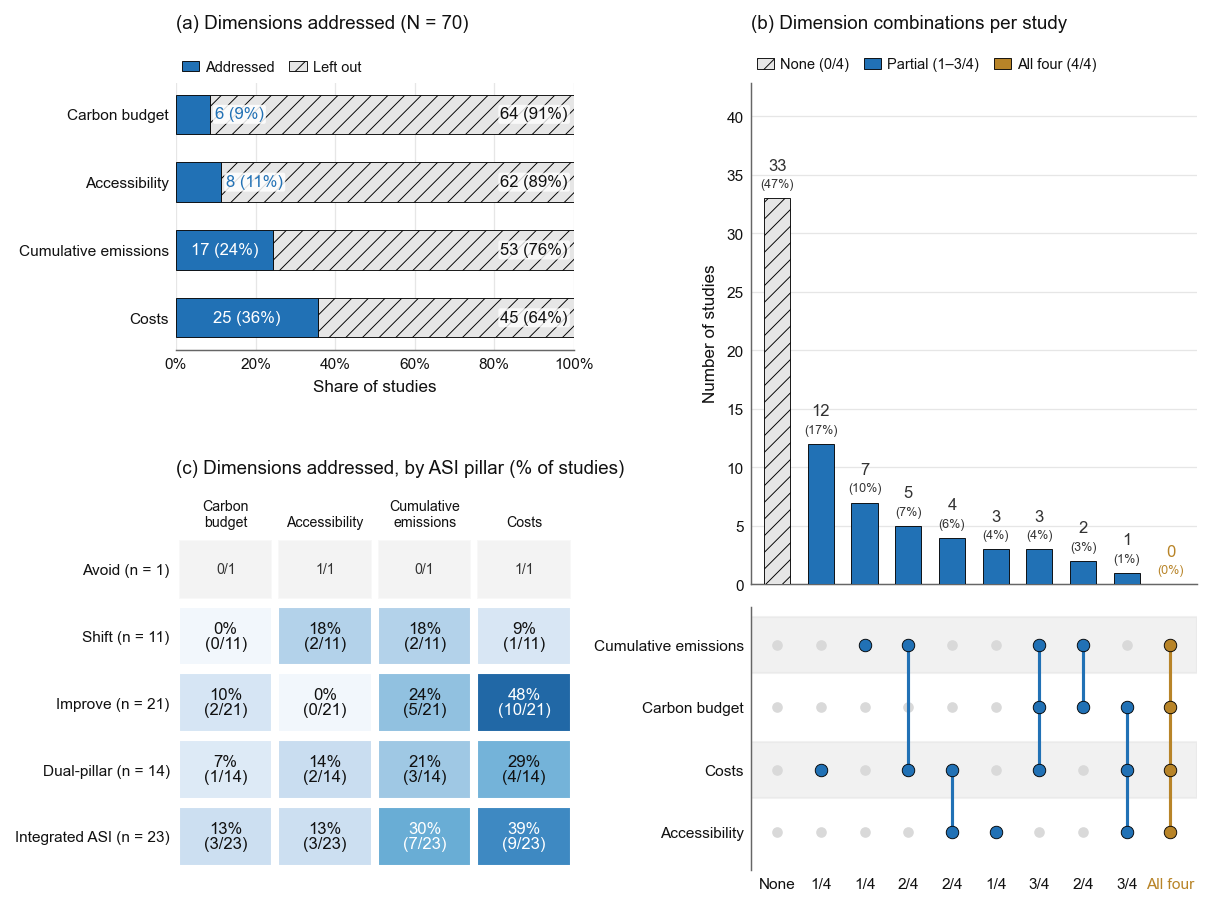

In [6]:
# %% [FIGURA 3.5 – WHAT THE LITERATURE LEAVES OUT] Cobertura de dimensiones + por pilar ASI + intersecciones (N = 70)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import LinearSegmentedColormap

# ==============================================================================
# 0. RUTAS, PARÁMETROS Y LECTURA ESTRICTA DEL DATASET
# ==============================================================================
DARK_MODE = False
BOLD_TITLES = False           # False -> títulos de panel en regular (sin negrita)
FS = 1.0                      # Escala de TODAS las fuentes
FIGSIZE = (8.4, 6.4)          # 8.4 in de ancho -> \textwidth (factor 0.75), como el resto de figuras
MIN_N_ROW = 3                 # pilares con n < 3 no se porcentúan (se muestran atenuados)

INFILE = Path("/Users/joanpau/Documents/00_Inbox/SLR - Results Points/SLR Extraction Sheet.xlsx")
if not INFILE.exists():
    raise FileNotFoundError(f"No se encontró el archivo en: {INFILE}")
OUTDIR = INFILE.parent / "Images"
OUTDIR.mkdir(exist_ok=True)

df = pd.read_excel(INFILE, sheet_name="Extraction").dropna(subset=["ID"])
df["ID"] = df["ID"].astype(str).str.strip()
N_TOTAL = len(df)
assert df["ID"].is_unique, "IDs duplicados en el dataset"

DIM_NAMES = ["Cumulative emissions", "Carbon budget", "Costs", "Accessibility"]
missing = [c for c in DIM_NAMES if c not in df.columns]
assert not missing, f"Faltan columnas en 'Extraction': {missing}"

def yn_flag(series, name):
    """Y -> True, N -> False. Cualquier otro valor (vacío, 'Partial', ...) detiene el script:
    así ningún estudio se cuenta en silencio como incluido u omitido."""
    s = series.fillna("").astype(str).str.strip().str.upper()
    bad = sorted(set(s) - {"Y", "N"})
    assert not bad, f"Valores no Y/N en '{name}': {bad} -> IDs {df.loc[~s.isin(['Y', 'N']), 'ID'].tolist()}"
    return s.eq("Y")

flags = pd.DataFrame({d: yn_flag(df[d], d) for d in DIM_NAMES})
flags.index = df["ID"]

ASI_5_ORDER = ["Avoid", "Shift", "Improve", "Dual-pillar", "Integrated ASI"]
PILLAR_5_MAP = {"A": "Avoid", "S": "Shift", "I": "Improve",
                "A+S": "Dual-pillar", "A+I": "Dual-pillar", "S+I": "Dual-pillar",
                "A+S+I": "Integrated ASI"}
pillar = df["Pillar"].astype(str).str.strip().map(PILLAR_5_MAP)
pillar.index = df["ID"]
assert pillar.isna().sum() == 0, f"Pilares sin mapear: {pillar[pillar.isna()].index.tolist()}"

# ==============================================================================
# 1. PALETA Y TIPOGRAFÍA (misma familia que el resto del paper)
# ==============================================================================
BG_COL    = "#000000" if DARK_MODE else "#FFFFFF"
FG_COL    = "#FFFFFF" if DARK_MODE else "#111111"
SUB_COL   = "#D9D9D9" if DARK_MODE else "#333333"
EDGE_COL  = "#FFFFFF" if DARK_MODE else "#000000"
GRID_COL  = "#222222" if DARK_MODE else "0.90"
SPINE_COL = "#888888" if DARK_MODE else "0.40"
BLUE_INC  = "#2b7bba" if DARK_MODE else "#2171b5"
GREY_OMIT = "#262626" if DARK_MODE else "#e6e6e6"
GOLD_ALL4 = "#f2be54" if DARK_MODE else "#b88428"
DOT_OFF   = "#3a3a3a" if DARK_MODE else "#d9d9d9"
HEAT_CMAP = LinearSegmentedColormap.from_list("blues_paper", ["#f2f7fc", "#c6dbef", "#6baed6",
                                                              "#2171b5", "#1f3f63"])

F_TITLE, F_LABEL, F_TICK, F_LEG, F_ANN = 9.0 * FS, 8.2 * FS, 7.4 * FS, 7.0 * FS, 6.8 * FS
F_NUM = 8.0 * FS              # tamaño de los números (etiquetas de datos)
TITLE_PAD = 26 * FS

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": F_TICK, "axes.labelsize": F_LABEL, "axes.titlesize": F_TITLE,
    "xtick.labelsize": F_TICK, "ytick.labelsize": F_TICK, "legend.fontsize": F_LEG,
    "axes.linewidth": 0.7, "hatch.linewidth": 0.45, "hatch.color": EDGE_COL,
    "figure.facecolor": BG_COL, "axes.facecolor": BG_COL, "savefig.facecolor": BG_COL,
    "text.color": FG_COL, "axes.labelcolor": FG_COL, "xtick.color": FG_COL, "ytick.color": FG_COL,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

def clean_ax(ax, grid_axis=None):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(SPINE_COL)
    ax.spines["bottom"].set_color(SPINE_COL)
    if grid_axis == "y":
        ax.yaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    elif grid_axis == "x":
        ax.xaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=FG_COL)

def panel_title(ax, text, pad=TITLE_PAD):
    ax.set_title(text, fontsize=F_TITLE, fontweight="bold" if BOLD_TITLES else "normal", pad=pad,
                 loc="left", color=FG_COL)

def top_legend(ax, handles, ncol):
    leg = ax.legend(handles=handles, ncol=ncol, frameon=False, fontsize=F_LEG, handlelength=1.2,
                    columnspacing=1.0, handletextpad=0.4, loc="lower left",
                    bbox_to_anchor=(0.0, 1.01), borderaxespad=0)
    for txt in leg.get_texts():
        txt.set_color(FG_COL)
    return leg

# ==============================================================================
# 2. MAQUETACIÓN: izquierda = cobertura (arriba) + por pilar (abajo) | derecha = intersecciones
# ==============================================================================
fig = plt.figure(figsize=FIGSIZE, dpi=150, facecolor=BG_COL)
gs_main = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.0, 1.12], wspace=0.42,
                            left=0.17, right=0.98, top=0.90, bottom=0.08)
gs_l = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs_main[0], height_ratios=[1.0, 1.25],
                                        hspace=0.62)
gs_r = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs_main[1], height_ratios=[2.2, 1.15],
                                        hspace=0.06)
ax_a = fig.add_subplot(gs_l[0])
ax_c = fig.add_subplot(gs_l[1])
ax_b_top = fig.add_subplot(gs_r[0])
ax_b_mat = fig.add_subplot(gs_r[1], sharex=ax_b_top)

# ------------------------------------------------------------------------------
# PANEL (a): Dimensiones abordadas vs omitidas (N = 70)
# ------------------------------------------------------------------------------
inc_counts = flags.sum().reindex(DIM_NAMES).values.astype(int)
omit_counts = N_TOTAL - inc_counts
order_a = np.argsort(-omit_counts, kind="stable")[::-1]        # mayor omisión arriba
dims_sorted = [DIM_NAMES[i] for i in order_a]
inc_sorted, omit_sorted = inc_counts[order_a], omit_counts[order_a]
inc_pct, omit_pct = 100.0 * inc_sorted / N_TOTAL, 100.0 * omit_sorted / N_TOTAL

y_a = np.arange(len(dims_sorted))
ax_a.barh(y_a, inc_pct, height=0.58, color=BLUE_INC, edgecolor=EDGE_COL, linewidth=0.42,
          zorder=3)
ax_a.barh(y_a, omit_pct, left=inc_pct, height=0.58, color=GREY_OMIT, edgecolor=EDGE_COL,
          linewidth=0.42, hatch="///", zorder=3)
for yi, ic, ip, oc, op in zip(y_a, inc_sorted, inc_pct, omit_sorted, omit_pct):
    if ip >= 16:
        ax_a.text(ip / 2, yi, f"{ic} ({ip:.0f}%)", va="center", ha="center", fontsize=F_NUM,
                  color="#FFFFFF", zorder=4)
    else:                                       # barra estrecha: etiqueta justo a su derecha
        ax_a.text(ip + 1.2, yi, f"{ic} ({ip:.0f}%)", va="center", ha="left", fontsize=F_NUM,
                  color=BLUE_INC, zorder=4,
                  bbox=dict(boxstyle="round,pad=0.12", facecolor=BG_COL, edgecolor="none",
                            alpha=0.85))
    ax_a.text(100 - 1.5, yi, f"{oc} ({op:.0f}%)", va="center", ha="right", fontsize=F_NUM,
              color=FG_COL, zorder=4,
              bbox=dict(boxstyle="round,pad=0.12", facecolor=BG_COL, edgecolor="none", alpha=0.8))

ax_a.set_yticks(y_a)
ax_a.set_yticklabels(dims_sorted)
ax_a.set_xlim(0, 100)
ax_a.set_xticks(range(0, 101, 20))
ax_a.set_xticklabels([f"{v}%" for v in range(0, 101, 20)])
ax_a.set_xlabel("Share of studies", fontsize=F_LABEL)
clean_ax(ax_a, grid_axis="x")
ax_a.spines["left"].set_visible(False)
panel_title(ax_a, f"(a) Dimensions addressed (N = {N_TOTAL})")
top_legend(ax_a, [Patch(facecolor=BLUE_INC, edgecolor=EDGE_COL, linewidth=0.42,
                        label="Addressed"),
                  Patch(facecolor=GREY_OMIT, edgecolor=EDGE_COL, linewidth=0.42, hatch="///",
                        label="Left out")], ncol=2)

# ------------------------------------------------------------------------------
# PANEL (c): Cobertura de cada dimensión por pilar ASI (% de estudios del pilar)
# ------------------------------------------------------------------------------
heat_rows = ASI_5_ORDER
n_pillar = pillar.value_counts().reindex(heat_rows).fillna(0).astype(int)
k_pd = flags.groupby(pillar).sum().reindex(index=heat_rows, columns=DIM_NAMES).fillna(0).astype(int)
pct_pd = k_pd.div(n_pillar, axis=0) * 100
dims_c = dims_sorted[::-1]                              # mismo orden que el panel superior (arriba->abajo)

for i, p in enumerate(heat_rows):
    for j, d in enumerate(dims_c):
        k, n = int(k_pd.loc[p, d]), int(n_pillar[p])
        small = n < MIN_N_ROW
        val = pct_pd.loc[p, d]
        fc = GREY_OMIT if small else HEAT_CMAP(min(val, 60) / 60)
        ax_c.add_patch(plt.Rectangle((j - 0.47, i - 0.44), 0.94, 0.88, facecolor=fc,
                                     edgecolor=BG_COL, linewidth=1.0, alpha=0.45 if small else 1))
        if small:
            txt, col = f"{k}/{n}", SUB_COL
        else:
            txt = f"{val:.0f}%\n({k}/{n})"
            col = "#FFFFFF" if val >= 30 else FG_COL
        ax_c.text(j, i, txt, ha="center", va="center", fontsize=F_NUM if not small else F_ANN,
                  color=col, linespacing=1.0)

ax_c.set_xlim(-0.5, len(dims_c) - 0.5)
ax_c.set_ylim(len(heat_rows) - 0.5, -0.5)
ax_c.set_xticks(range(len(dims_c)))
ax_c.set_xticklabels([d.replace(" ", "\n", 1) for d in dims_c], fontsize=F_ANN)
ax_c.xaxis.tick_top()
ax_c.set_yticks(range(len(heat_rows)))
ax_c.set_yticklabels([f"{p} (n = {n_pillar[p]})" for p in heat_rows])
for s in ax_c.spines.values():
    s.set_visible(False)
ax_c.tick_params(length=0, pad=3)
panel_title(ax_c, "(c) Dimensions addressed, by ASI pillar (% of studies)", pad=30 * FS)

# ------------------------------------------------------------------------------
# PANEL (b): Intersecciones entre dimensiones (UpSet, N = 70)
# ------------------------------------------------------------------------------
combos = flags[DIM_NAMES].value_counts().reset_index(name="count")
combos["n_active"] = combos[DIM_NAMES].sum(axis=1)
if not (combos["n_active"] == 4).any():                 # la intersección completa se muestra aunque sea 0
    combos = pd.concat([combos, pd.DataFrame([{**{d: True for d in DIM_NAMES},
                                               "count": 0, "n_active": 4}])], ignore_index=True)
combos_non4 = combos[combos["n_active"] < 4].sort_values(
    ["count", "n_active"] + DIM_NAMES, ascending=[False, True] + [False] * len(DIM_NAMES))
combos = pd.concat([combos_non4, combos[combos["n_active"] == 4]], ignore_index=True)
assert int(combos["count"].sum()) == N_TOTAL, "La suma de combinaciones no coincide con N"

x_b = np.arange(len(combos))
def combo_color(n):
    return GOLD_ALL4 if n == 4 else (GREY_OMIT if n == 0 else BLUE_INC)

for xi, row in combos.iterrows():
    ax_b_top.bar(xi, row["count"], width=0.6, color=combo_color(row["n_active"]),
                 edgecolor=EDGE_COL, linewidth=0.42, hatch="///" if row["n_active"] == 0 else "",
                 zorder=3)
    cnt = int(row["count"])
    col_lbl = GOLD_ALL4 if row["n_active"] == 4 else SUB_COL
    y_lbl = cnt + combos["count"].max() * 0.02
    # número grande arriba; porcentaje debajo y algo menor para que no choque con la barra vecina
    ax_b_top.annotate(f"{cnt}", (xi, y_lbl), xytext=(0, 8.5 * FS), textcoords="offset points",
                      ha="center", va="bottom", fontsize=F_NUM, color=col_lbl)
    ax_b_top.text(xi, y_lbl, f"({100 * cnt / N_TOTAL:.0f}%)", ha="center", va="bottom",
                  fontsize=F_ANN - 0.8, color=col_lbl)

ax_b_top.set_ylabel("Number of studies", fontsize=F_LABEL)
ax_b_top.set_ylim(0, combos["count"].max() * 1.30)
ax_b_top.yaxis.set_major_locator(MaxNLocator(integer=True))
clean_ax(ax_b_top, grid_axis="y")
plt.setp(ax_b_top.get_xticklabels(), visible=False)
panel_title(ax_b_top, "(b) Dimension combinations per study")
top_legend(ax_b_top, [
    Patch(facecolor=GREY_OMIT, edgecolor=EDGE_COL, linewidth=0.42, hatch="///", label="None (0/4)"),
    Patch(facecolor=BLUE_INC, edgecolor=EDGE_COL, linewidth=0.42, label="Partial (1–3/4)"),
    Patch(facecolor=GOLD_ALL4, edgecolor=EDGE_COL, linewidth=0.42, label="All four (4/4)")],
    ncol=3)

# Matriz de intersección
# De arriba a abajo: Cumulative emissions, Carbon budget, Costs, Accessibility (y crece hacia arriba)
MAT_ORDER_TOP_DOWN = ["Cumulative emissions", "Carbon budget", "Costs", "Accessibility"]
mat_dims = MAT_ORDER_TOP_DOWN[::-1]
y_mat = np.arange(len(mat_dims))
for yi in y_mat:
    if yi % 2 == 1:
        ax_b_mat.axhspan(yi - 0.45, yi + 0.45, color=GRID_COL, alpha=0.55, zorder=0)
for xi, row in combos.iterrows():
    on = [yi for yi, d in enumerate(mat_dims) if row[d]]
    off = [yi for yi, d in enumerate(mat_dims) if not row[d]]
    ax_b_mat.scatter([xi] * len(off), off, s=26, color=DOT_OFF, zorder=2, linewidths=0)
    if on:
        col = GOLD_ALL4 if row["n_active"] == 4 else BLUE_INC
        if len(on) > 1:
            ax_b_mat.plot([xi, xi], [min(on), max(on)], color=col, linewidth=1.5, zorder=3)
        ax_b_mat.scatter([xi] * len(on), on, s=36, color=col, edgecolor=EDGE_COL,
                         linewidth=0.42, zorder=4)

x_labels = ["None" if r["n_active"] == 0 else ("All four" if r["n_active"] == 4
            else f"{int(r['n_active'])}/4") for _, r in combos.iterrows()]
ax_b_mat.set_yticks(y_mat)
ax_b_mat.set_yticklabels(mat_dims, fontsize=F_TICK)
ax_b_mat.set_ylim(-0.6, len(mat_dims) - 0.4)
ax_b_mat.set_xticks(x_b)
ax_b_mat.set_xticklabels(x_labels, fontsize=F_TICK)
ax_b_mat.set_xlim(-0.6, len(combos) - 0.4)
for s in ["top", "right", "bottom"]:
    ax_b_mat.spines[s].set_visible(False)
ax_b_mat.spines["left"].set_color(SPINE_COL)          # barra que separa las etiquetas de la matriz
ax_b_mat.tick_params(length=0, colors=FG_COL)
for t in ax_b_mat.get_xticklabels():
    if t.get_text() == "All four":
        t.set_color(GOLD_ALL4)

# ==============================================================================
# 3. EXPORTACIÓN Y CIFRAS PARA EL TEXTO (todas leídas del dataset)
# ==============================================================================
stem = (f"fig_literature_gaps{N_TOTAL}" + ("" if BOLD_TITLES else "_regular")
        + ("_dark" if DARK_MODE else ""))
for ext in ["pdf", "png", "svg"]:
    fig.savefig(OUTDIR / f"{stem}.{ext}", dpi=600 if ext == "png" else 300,
                bbox_inches="tight", pad_inches=0.04, facecolor=BG_COL, edgecolor="none")

n_dims = flags.sum(axis=1)
print(f"Archivos guardados en: {OUTDIR}/{stem}.{{pdf,png,svg}}")
print(f"\nN = {N_TOTAL}")
print("Estudios que abordan cada dimensión:", dict(zip(DIM_NAMES, flags.sum().astype(int))))
print("Nº de dimensiones por estudio:", n_dims.value_counts().sort_index().to_dict())
print("Las cuatro:", int((n_dims == 4).sum()), "| ninguna:", int((n_dims == 0).sum()))
print("\nPor pilar (k de n):\n", k_pd.assign(n=n_pillar).to_string())
print("\nEstudios con >= 3 dimensiones:", n_dims[n_dims >= 3].index.tolist())
plt.show()

Archivos guardados en: /Users/joanpau/Documents/00_Inbox/SLR - Results Points/Images/fig_literature_gaps70.{pdf,png,svg}

N = 70
Estudios que abordan cada dimensión: {'Cumulative emissions': 17, 'Carbon budget': 6, 'Costs': 25, 'Accessibility': 8}
Nº de dimensiones por estudio: {0: 33, 1: 22, 2: 11, 3: 4}
Las cuatro: 0 | ninguna: 33

Por pilar (k de n):
                 Cumulative emissions  Carbon budget  Costs  Accessibility   n
Pillar                                                                       
Avoid                              0              0      1              1   1
Shift                              2              0      1              2  11
Improve                            5              2     10              0  21
Dual-pillar                        3              1      4              2  14
Integrated ASI                     7              3      9              3  23

Estudios con >= 3 dimensiones: ['S10', 'S13', 'S29', 'S34']


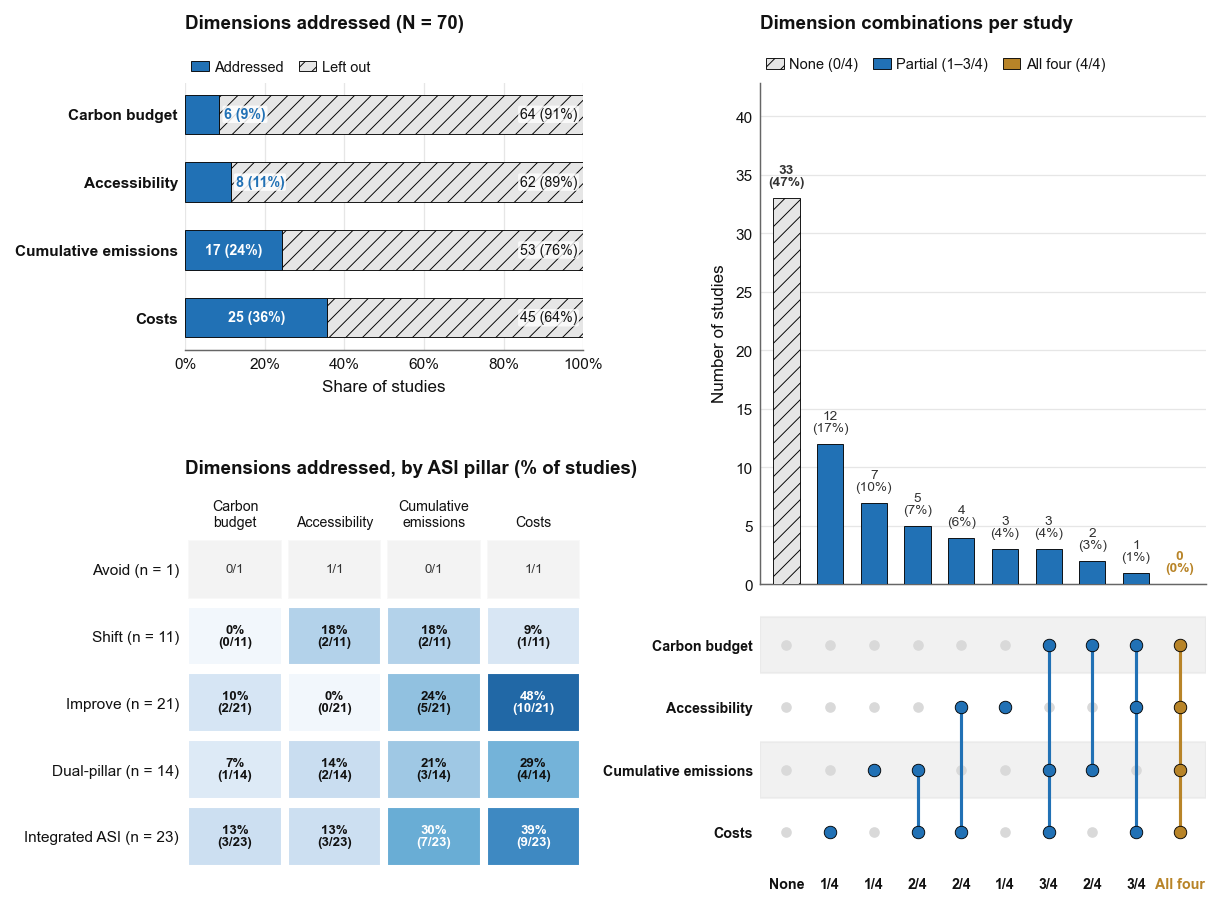

In [1]:
# %% [FIGURA 3.5 – WHAT THE LITERATURE LEAVES OUT] Cobertura de dimensiones + por pilar ASI + intersecciones (N = 70)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import LinearSegmentedColormap

# ==============================================================================
# 0. RUTAS, PARÁMETROS Y LECTURA ESTRICTA DEL DATASET
# ==============================================================================
DARK_MODE = False
FS = 1.0                      # Escala de TODAS las fuentes
FIGSIZE = (8.4, 6.4)          # 8.4 in de ancho -> \textwidth (factor 0.75), como el resto de figuras
MIN_N_ROW = 3                 # pilares con n < 3 no se porcentúan (se muestran atenuados)

INFILE = Path("/Users/joanpau/Documents/00_Inbox/SLR - Results Points/SLR Extraction Sheet.xlsx")
if not INFILE.exists():
    raise FileNotFoundError(f"No se encontró el archivo en: {INFILE}")
OUTDIR = INFILE.parent / "Images"
OUTDIR.mkdir(exist_ok=True)

df = pd.read_excel(INFILE, sheet_name="Extraction").dropna(subset=["ID"])
df["ID"] = df["ID"].astype(str).str.strip()
N_TOTAL = len(df)
assert df["ID"].is_unique, "IDs duplicados en el dataset"

DIM_NAMES = ["Cumulative emissions", "Carbon budget", "Costs", "Accessibility"]
missing = [c for c in DIM_NAMES if c not in df.columns]
assert not missing, f"Faltan columnas en 'Extraction': {missing}"

def yn_flag(series, name):
    """Y -> True, N -> False. Cualquier otro valor (vacío, 'Partial', ...) detiene el script:
    así ningún estudio se cuenta en silencio como incluido u omitido."""
    s = series.fillna("").astype(str).str.strip().str.upper()
    bad = sorted(set(s) - {"Y", "N"})
    assert not bad, f"Valores no Y/N en '{name}': {bad} -> IDs {df.loc[~s.isin(['Y', 'N']), 'ID'].tolist()}"
    return s.eq("Y")

flags = pd.DataFrame({d: yn_flag(df[d], d) for d in DIM_NAMES})
flags.index = df["ID"]

ASI_5_ORDER = ["Avoid", "Shift", "Improve", "Dual-pillar", "Integrated ASI"]
PILLAR_5_MAP = {"A": "Avoid", "S": "Shift", "I": "Improve",
                "A+S": "Dual-pillar", "A+I": "Dual-pillar", "S+I": "Dual-pillar",
                "A+S+I": "Integrated ASI"}
pillar = df["Pillar"].astype(str).str.strip().map(PILLAR_5_MAP)
pillar.index = df["ID"]
assert pillar.isna().sum() == 0, f"Pilares sin mapear: {pillar[pillar.isna()].index.tolist()}"

# ==============================================================================
# 1. PALETA Y TIPOGRAFÍA (misma familia que el resto del paper)
# ==============================================================================
BG_COL    = "#000000" if DARK_MODE else "#FFFFFF"
FG_COL    = "#FFFFFF" if DARK_MODE else "#111111"
SUB_COL   = "#D9D9D9" if DARK_MODE else "#333333"
EDGE_COL  = "#FFFFFF" if DARK_MODE else "#000000"
GRID_COL  = "#222222" if DARK_MODE else "0.90"
SPINE_COL = "#888888" if DARK_MODE else "0.40"
BLUE_INC  = "#2b7bba" if DARK_MODE else "#2171b5"
GREY_OMIT = "#262626" if DARK_MODE else "#e6e6e6"
GOLD_ALL4 = "#f2be54" if DARK_MODE else "#b88428"
DOT_OFF   = "#3a3a3a" if DARK_MODE else "#d9d9d9"
HEAT_CMAP = LinearSegmentedColormap.from_list("blues_paper", ["#f2f7fc", "#c6dbef", "#6baed6",
                                                              "#2171b5", "#1f3f63"])

F_TITLE, F_LABEL, F_TICK, F_LEG, F_ANN = 9.0 * FS, 8.2 * FS, 7.4 * FS, 7.0 * FS, 6.8 * FS
TITLE_PAD = 26 * FS

# Arial primero: en macOS "Helvetica.ttc" no expone la negrita a matplotlib.
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": F_TICK, "axes.labelsize": F_LABEL, "axes.titlesize": F_TITLE,
    "xtick.labelsize": F_TICK, "ytick.labelsize": F_TICK, "legend.fontsize": F_LEG,
    "axes.linewidth": 0.7, "hatch.linewidth": 0.45, "hatch.color": EDGE_COL,
    "figure.facecolor": BG_COL, "axes.facecolor": BG_COL, "savefig.facecolor": BG_COL,
    "text.color": FG_COL, "axes.labelcolor": FG_COL, "xtick.color": FG_COL, "ytick.color": FG_COL,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

def clean_ax(ax, grid_axis=None):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(SPINE_COL)
    ax.spines["bottom"].set_color(SPINE_COL)
    if grid_axis == "y":
        ax.yaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    elif grid_axis == "x":
        ax.xaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=FG_COL)

def panel_title(ax, text, pad=TITLE_PAD):
    ax.set_title(text, fontsize=F_TITLE, fontweight="bold", pad=pad, loc="left", color=FG_COL)

def top_legend(ax, handles, ncol):
    leg = ax.legend(handles=handles, ncol=ncol, frameon=False, fontsize=F_LEG, handlelength=1.2,
                    columnspacing=1.0, handletextpad=0.4, loc="lower left",
                    bbox_to_anchor=(0.0, 1.01), borderaxespad=0)
    for txt in leg.get_texts():
        txt.set_color(FG_COL)
    return leg

# ==============================================================================
# 2. MAQUETACIÓN: izquierda = cobertura (arriba) + por pilar (abajo) | derecha = intersecciones
# ==============================================================================
fig = plt.figure(figsize=FIGSIZE, dpi=150, facecolor=BG_COL)
gs_main = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.0, 1.12], wspace=0.42,
                            left=0.17, right=0.98, top=0.90, bottom=0.08)
gs_l = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs_main[0], height_ratios=[1.0, 1.25],
                                        hspace=0.62)
gs_r = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs_main[1], height_ratios=[2.2, 1.15],
                                        hspace=0.06)
ax_a = fig.add_subplot(gs_l[0])
ax_c = fig.add_subplot(gs_l[1])
ax_b_top = fig.add_subplot(gs_r[0])
ax_b_mat = fig.add_subplot(gs_r[1], sharex=ax_b_top)

# ------------------------------------------------------------------------------
# PANEL: Dimensiones abordadas vs omitidas (N = 70)
# ------------------------------------------------------------------------------
inc_counts = flags.sum().reindex(DIM_NAMES).values.astype(int)
omit_counts = N_TOTAL - inc_counts
order_a = np.argsort(-omit_counts, kind="stable")[::-1]        # mayor omisión arriba
dims_sorted = [DIM_NAMES[i] for i in order_a]
inc_sorted, omit_sorted = inc_counts[order_a], omit_counts[order_a]
inc_pct, omit_pct = 100.0 * inc_sorted / N_TOTAL, 100.0 * omit_sorted / N_TOTAL

y_a = np.arange(len(dims_sorted))
ax_a.barh(y_a, inc_pct, height=0.58, color=BLUE_INC, edgecolor=EDGE_COL, linewidth=0.42,
          zorder=3)
ax_a.barh(y_a, omit_pct, left=inc_pct, height=0.58, color=GREY_OMIT, edgecolor=EDGE_COL,
          linewidth=0.42, hatch="///", zorder=3)
for yi, ic, ip, oc, op in zip(y_a, inc_sorted, inc_pct, omit_sorted, omit_pct):
    if ip >= 16:
        ax_a.text(ip / 2, yi, f"{ic} ({ip:.0f}%)", va="center", ha="center", fontsize=F_ANN,
                  fontweight="bold", color="#FFFFFF", zorder=4)
    else:                                       # barra estrecha: etiqueta justo a su derecha
        ax_a.text(ip + 1.2, yi, f"{ic} ({ip:.0f}%)", va="center", ha="left", fontsize=F_ANN,
                  fontweight="bold", color=BLUE_INC, zorder=4,
                  bbox=dict(boxstyle="round,pad=0.12", facecolor=BG_COL, edgecolor="none",
                            alpha=0.85))
    ax_a.text(100 - 1.5, yi, f"{oc} ({op:.0f}%)", va="center", ha="right", fontsize=F_ANN,
              color=FG_COL, zorder=4,
              bbox=dict(boxstyle="round,pad=0.12", facecolor=BG_COL, edgecolor="none", alpha=0.8))

ax_a.set_yticks(y_a)
ax_a.set_yticklabels(dims_sorted, fontweight="bold")
ax_a.set_xlim(0, 100)
ax_a.set_xticks(range(0, 101, 20))
ax_a.set_xticklabels([f"{v}%" for v in range(0, 101, 20)])
ax_a.set_xlabel("Share of studies", fontsize=F_LABEL)
clean_ax(ax_a, grid_axis="x")
ax_a.spines["left"].set_visible(False)
panel_title(ax_a, f"Dimensions addressed (N = {N_TOTAL})")
top_legend(ax_a, [Patch(facecolor=BLUE_INC, edgecolor=EDGE_COL, linewidth=0.42,
                        label="Addressed"),
                  Patch(facecolor=GREY_OMIT, edgecolor=EDGE_COL, linewidth=0.42, hatch="///",
                        label="Left out")], ncol=2)

# ------------------------------------------------------------------------------
# PANEL: Cobertura de cada dimensión por pilar ASI (% de estudios del pilar)
# ------------------------------------------------------------------------------
heat_rows = ASI_5_ORDER
n_pillar = pillar.value_counts().reindex(heat_rows).fillna(0).astype(int)
k_pd = flags.groupby(pillar).sum().reindex(index=heat_rows, columns=DIM_NAMES).fillna(0).astype(int)
pct_pd = k_pd.div(n_pillar, axis=0) * 100
dims_c = dims_sorted[::-1]                              # mismo orden que el panel superior (arriba->abajo)

for i, p in enumerate(heat_rows):
    for j, d in enumerate(dims_c):
        k, n = int(k_pd.loc[p, d]), int(n_pillar[p])
        small = n < MIN_N_ROW
        val = pct_pd.loc[p, d]
        fc = GREY_OMIT if small else HEAT_CMAP(min(val, 60) / 60)
        ax_c.add_patch(plt.Rectangle((j - 0.47, i - 0.44), 0.94, 0.88, facecolor=fc,
                                     edgecolor=BG_COL, linewidth=1.0, alpha=0.45 if small else 1))
        if small:
            txt, col = f"{k}/{n}", SUB_COL
        else:
            txt = f"{val:.0f}%\n({k}/{n})"
            col = "#FFFFFF" if val >= 30 else FG_COL
        ax_c.text(j, i, txt, ha="center", va="center", fontsize=F_ANN - 0.4, color=col,
                  linespacing=1.0, fontweight="bold" if not small else "normal")

ax_c.set_xlim(-0.5, len(dims_c) - 0.5)
ax_c.set_ylim(len(heat_rows) - 0.5, -0.5)
ax_c.set_xticks(range(len(dims_c)))
ax_c.set_xticklabels([d.replace(" ", "\n", 1) for d in dims_c], fontsize=F_ANN)
ax_c.xaxis.tick_top()
ax_c.set_yticks(range(len(heat_rows)))
ax_c.set_yticklabels([f"{p} (n = {n_pillar[p]})" for p in heat_rows])
for s in ax_c.spines.values():
    s.set_visible(False)
ax_c.tick_params(length=0, pad=3)
panel_title(ax_c, "Dimensions addressed, by ASI pillar (% of studies)", pad=30 * FS)

# ------------------------------------------------------------------------------
# PANEL: Intersecciones entre dimensiones (UpSet, N = 70)
# ------------------------------------------------------------------------------
combos = flags[DIM_NAMES].value_counts().reset_index(name="count")
combos["n_active"] = combos[DIM_NAMES].sum(axis=1)
if not (combos["n_active"] == 4).any():                 # la intersección completa se muestra aunque sea 0
    combos = pd.concat([combos, pd.DataFrame([{**{d: True for d in DIM_NAMES},
                                               "count": 0, "n_active": 4}])], ignore_index=True)
combos_non4 = combos[combos["n_active"] < 4].sort_values(
    ["count", "n_active"] + DIM_NAMES, ascending=[False, True] + [False] * len(DIM_NAMES))
combos = pd.concat([combos_non4, combos[combos["n_active"] == 4]], ignore_index=True)
assert int(combos["count"].sum()) == N_TOTAL, "La suma de combinaciones no coincide con N"

x_b = np.arange(len(combos))
def combo_color(n):
    return GOLD_ALL4 if n == 4 else (GREY_OMIT if n == 0 else BLUE_INC)

for xi, row in combos.iterrows():
    ax_b_top.bar(xi, row["count"], width=0.6, color=combo_color(row["n_active"]),
                 edgecolor=EDGE_COL, linewidth=0.42, hatch="///" if row["n_active"] == 0 else "",
                 zorder=3)
    cnt = int(row["count"])
    ax_b_top.text(xi, cnt + combos["count"].max() * 0.025, f"{cnt}\n({100 * cnt / N_TOTAL:.0f}%)",
                  ha="center", va="bottom", fontsize=F_ANN - 0.2, linespacing=1.0,
                  color=GOLD_ALL4 if row["n_active"] == 4 else SUB_COL,
                  fontweight="bold" if row["n_active"] in (0, 4) else "normal")

ax_b_top.set_ylabel("Number of studies", fontsize=F_LABEL)
ax_b_top.set_ylim(0, combos["count"].max() * 1.30)
ax_b_top.yaxis.set_major_locator(MaxNLocator(integer=True))
clean_ax(ax_b_top, grid_axis="y")
plt.setp(ax_b_top.get_xticklabels(), visible=False)
panel_title(ax_b_top, "Dimension combinations per study")
top_legend(ax_b_top, [
    Patch(facecolor=GREY_OMIT, edgecolor=EDGE_COL, linewidth=0.42, hatch="///", label="None (0/4)"),
    Patch(facecolor=BLUE_INC, edgecolor=EDGE_COL, linewidth=0.42, label="Partial (1–3/4)"),
    Patch(facecolor=GOLD_ALL4, edgecolor=EDGE_COL, linewidth=0.42, label="All four (4/4)")],
    ncol=3)

# Matriz de intersección
mat_dims = dims_c[::-1]                                   # misma ordenación que los otros paneles
y_mat = np.arange(len(mat_dims))
for yi in y_mat:
    if yi % 2 == 1:
        ax_b_mat.axhspan(yi - 0.45, yi + 0.45, color=GRID_COL, alpha=0.55, zorder=0)
for xi, row in combos.iterrows():
    on = [yi for yi, d in enumerate(mat_dims) if row[d]]
    off = [yi for yi, d in enumerate(mat_dims) if not row[d]]
    ax_b_mat.scatter([xi] * len(off), off, s=26, color=DOT_OFF, zorder=2, linewidths=0)
    if on:
        col = GOLD_ALL4 if row["n_active"] == 4 else BLUE_INC
        if len(on) > 1:
            ax_b_mat.plot([xi, xi], [min(on), max(on)], color=col, linewidth=1.5, zorder=3)
        ax_b_mat.scatter([xi] * len(on), on, s=36, color=col, edgecolor=EDGE_COL,
                         linewidth=0.42, zorder=4)

x_labels = ["None" if r["n_active"] == 0 else ("All four" if r["n_active"] == 4
            else f"{int(r['n_active'])}/4") for _, r in combos.iterrows()]
ax_b_mat.set_yticks(y_mat)
ax_b_mat.set_yticklabels(mat_dims, fontsize=F_ANN, fontweight="bold")
ax_b_mat.set_ylim(-0.6, len(mat_dims) - 0.4)
ax_b_mat.set_xticks(x_b)
ax_b_mat.set_xticklabels(x_labels, fontsize=F_ANN, fontweight="bold")
ax_b_mat.set_xlim(-0.6, len(combos) - 0.4)
for s in ["top", "right", "bottom", "left"]:
    ax_b_mat.spines[s].set_visible(False)
ax_b_mat.tick_params(length=0, colors=FG_COL)
for t in ax_b_mat.get_xticklabels():
    if t.get_text() == "All four":
        t.set_color(GOLD_ALL4)

# ==============================================================================
# 3. EXPORTACIÓN Y CIFRAS PARA EL TEXTO (todas leídas del dataset)
# ==============================================================================
stem = f"fig_literature_gaps{N_TOTAL}" + ("_dark" if DARK_MODE else "")
for ext in ["pdf", "png", "svg"]:
    fig.savefig(OUTDIR / f"{stem}.{ext}", dpi=600 if ext == "png" else 300,
                bbox_inches="tight", pad_inches=0.04, facecolor=BG_COL, edgecolor="none")

n_dims = flags.sum(axis=1)
print(f"Archivos guardados en: {OUTDIR}/{stem}.{{pdf,png,svg}}")
print(f"\nN = {N_TOTAL}")
print("Estudios que abordan cada dimensión:", dict(zip(DIM_NAMES, flags.sum().astype(int))))
print("Nº de dimensiones por estudio:", n_dims.value_counts().sort_index().to_dict())
print("Las cuatro:", int((n_dims == 4).sum()), "| ninguna:", int((n_dims == 0).sum()))
print("\nPor pilar (k de n):\n", k_pd.assign(n=n_pillar).to_string())
print("\nEstudios con >= 3 dimensiones:", n_dims[n_dims >= 3].index.tolist())
plt.show()

Archivos guardados en: /Users/joanpau/Documents/00_Inbox/SLR - Results Points/Images/fig_literature_gaps70.{pdf,png,svg}

N = 70
Estudios que abordan cada dimensión: {'Cumulative emissions': 17, 'Carbon budget': 6, 'Costs': 25, 'Accessibility': 8}
Nº de dimensiones por estudio: {0: 33, 1: 22, 2: 11, 3: 4}
Las cuatro: 0 | ninguna: 33

Por pilar (k de n):
                 Cumulative emissions  Carbon budget  Costs  Accessibility   n
Pillar                                                                       
Avoid                              0              0      1              1   1
Shift                              2              0      1              2  11
Improve                            5              2     10              0  21
Dual-pillar                        3              1      4              2  14
Integrated ASI                     7              3      9              3  23

Estudios con >= 3 dimensiones: ['S10', 'S13', 'S29', 'S34']


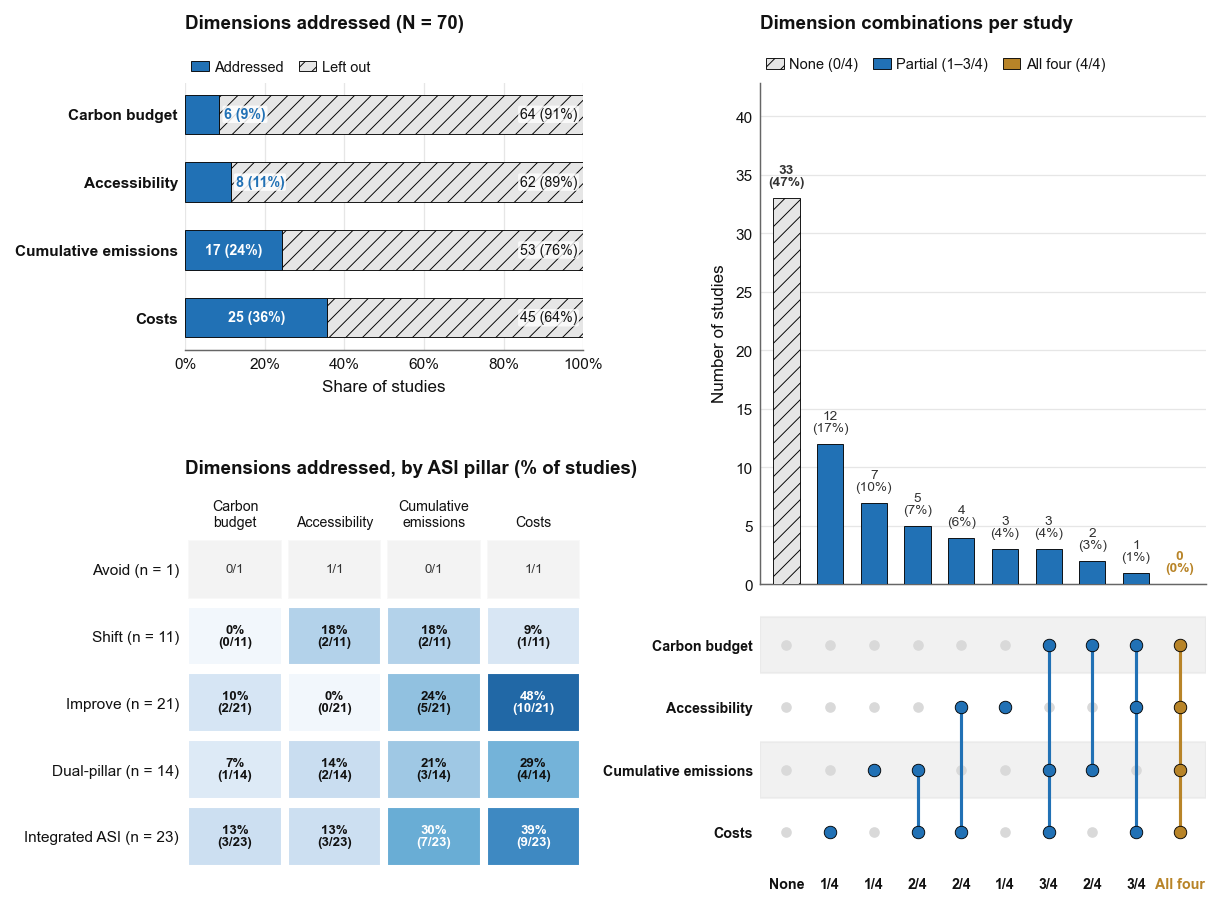

In [2]:
# %% [FIGURA 3.5 – WHAT THE LITERATURE LEAVES OUT] Cobertura de dimensiones + por pilar ASI + intersecciones (N = 70)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import LinearSegmentedColormap

# ==============================================================================
# 0. RUTAS, PARÁMETROS Y LECTURA ESTRICTA DEL DATASET
# ==============================================================================
DARK_MODE = False
FS = 1.0                      # Escala de TODAS las fuentes
FIGSIZE = (8.4, 6.4)          # 8.4 in de ancho -> \textwidth (factor 0.75), como el resto de figuras
MIN_N_ROW = 3                 # pilares con n < 3 no se porcentúan (se muestran atenuados)

INFILE = Path("/Users/joanpau/Documents/00_Inbox/SLR - Results Points/SLR Extraction Sheet.xlsx")
if not INFILE.exists():
    raise FileNotFoundError(f"No se encontró el archivo en: {INFILE}")
OUTDIR = INFILE.parent / "Images"
OUTDIR.mkdir(exist_ok=True)

df = pd.read_excel(INFILE, sheet_name="Extraction").dropna(subset=["ID"])
df["ID"] = df["ID"].astype(str).str.strip()
N_TOTAL = len(df)
assert df["ID"].is_unique, "IDs duplicados en el dataset"

DIM_NAMES = ["Cumulative emissions", "Carbon budget", "Costs", "Accessibility"]
missing = [c for c in DIM_NAMES if c not in df.columns]
assert not missing, f"Faltan columnas en 'Extraction': {missing}"

def yn_flag(series, name):
    """Y -> True, N -> False. Cualquier otro valor (vacío, 'Partial', ...) detiene el script:
    así ningún estudio se cuenta en silencio como incluido u omitido."""
    s = series.fillna("").astype(str).str.strip().str.upper()
    bad = sorted(set(s) - {"Y", "N"})
    assert not bad, f"Valores no Y/N en '{name}': {bad} -> IDs {df.loc[~s.isin(['Y', 'N']), 'ID'].tolist()}"
    return s.eq("Y")

flags = pd.DataFrame({d: yn_flag(df[d], d) for d in DIM_NAMES})
flags.index = df["ID"]

ASI_5_ORDER = ["Avoid", "Shift", "Improve", "Dual-pillar", "Integrated ASI"]
PILLAR_5_MAP = {"A": "Avoid", "S": "Shift", "I": "Improve",
                "A+S": "Dual-pillar", "A+I": "Dual-pillar", "S+I": "Dual-pillar",
                "A+S+I": "Integrated ASI"}
pillar = df["Pillar"].astype(str).str.strip().map(PILLAR_5_MAP)
pillar.index = df["ID"]
assert pillar.isna().sum() == 0, f"Pilares sin mapear: {pillar[pillar.isna()].index.tolist()}"

# ==============================================================================
# 1. PALETA Y TIPOGRAFÍA (misma familia que el resto del paper)
# ==============================================================================
BG_COL    = "#000000" if DARK_MODE else "#FFFFFF"
FG_COL    = "#FFFFFF" if DARK_MODE else "#111111"
SUB_COL   = "#D9D9D9" if DARK_MODE else "#333333"
EDGE_COL  = "#FFFFFF" if DARK_MODE else "#000000"
GRID_COL  = "#222222" if DARK_MODE else "0.90"
SPINE_COL = "#888888" if DARK_MODE else "0.40"
BLUE_INC  = "#2b7bba" if DARK_MODE else "#2171b5"
GREY_OMIT = "#262626" if DARK_MODE else "#e6e6e6"
GOLD_ALL4 = "#f2be54" if DARK_MODE else "#b88428"
DOT_OFF   = "#3a3a3a" if DARK_MODE else "#d9d9d9"
HEAT_CMAP = LinearSegmentedColormap.from_list("blues_paper", ["#f2f7fc", "#c6dbef", "#6baed6",
                                                              "#2171b5", "#1f3f63"])

F_TITLE, F_LABEL, F_TICK, F_LEG, F_ANN = 9.0 * FS, 8.2 * FS, 7.4 * FS, 7.0 * FS, 6.8 * FS
TITLE_PAD = 26 * FS

# Arial primero: en macOS "Helvetica.ttc" no expone la negrita a matplotlib.
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": F_TICK, "axes.labelsize": F_LABEL, "axes.titlesize": F_TITLE,
    "xtick.labelsize": F_TICK, "ytick.labelsize": F_TICK, "legend.fontsize": F_LEG,
    "axes.linewidth": 0.7, "hatch.linewidth": 0.45, "hatch.color": EDGE_COL,
    "figure.facecolor": BG_COL, "axes.facecolor": BG_COL, "savefig.facecolor": BG_COL,
    "text.color": FG_COL, "axes.labelcolor": FG_COL, "xtick.color": FG_COL, "ytick.color": FG_COL,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

def clean_ax(ax, grid_axis=None):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(SPINE_COL)
    ax.spines["bottom"].set_color(SPINE_COL)
    if grid_axis == "y":
        ax.yaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    elif grid_axis == "x":
        ax.xaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=FG_COL)

def panel_title(ax, text, pad=TITLE_PAD):
    ax.set_title(text, fontsize=F_TITLE, fontweight="bold", pad=pad, loc="left", color=FG_COL)

def top_legend(ax, handles, ncol):
    leg = ax.legend(handles=handles, ncol=ncol, frameon=False, fontsize=F_LEG, handlelength=1.2,
                    columnspacing=1.0, handletextpad=0.4, loc="lower left",
                    bbox_to_anchor=(0.0, 1.01), borderaxespad=0)
    for txt in leg.get_texts():
        txt.set_color(FG_COL)
    return leg

# ==============================================================================
# 2. MAQUETACIÓN: izquierda = cobertura (arriba) + por pilar (abajo) | derecha = intersecciones
# ==============================================================================
fig = plt.figure(figsize=FIGSIZE, dpi=150, facecolor=BG_COL)
gs_main = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.0, 1.12], wspace=0.42,
                            left=0.17, right=0.98, top=0.90, bottom=0.08)
gs_l = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs_main[0], height_ratios=[1.0, 1.25],
                                        hspace=0.62)
gs_r = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs_main[1], height_ratios=[2.2, 1.15],
                                        hspace=0.06)
ax_a = fig.add_subplot(gs_l[0])
ax_c = fig.add_subplot(gs_l[1])
ax_b_top = fig.add_subplot(gs_r[0])
ax_b_mat = fig.add_subplot(gs_r[1], sharex=ax_b_top)

# ------------------------------------------------------------------------------
# PANEL: Dimensiones abordadas vs omitidas (N = 70)
# ------------------------------------------------------------------------------
inc_counts = flags.sum().reindex(DIM_NAMES).values.astype(int)
omit_counts = N_TOTAL - inc_counts
order_a = np.argsort(-omit_counts, kind="stable")[::-1]        # mayor omisión arriba
dims_sorted = [DIM_NAMES[i] for i in order_a]
inc_sorted, omit_sorted = inc_counts[order_a], omit_counts[order_a]
inc_pct, omit_pct = 100.0 * inc_sorted / N_TOTAL, 100.0 * omit_sorted / N_TOTAL

y_a = np.arange(len(dims_sorted))
ax_a.barh(y_a, inc_pct, height=0.58, color=BLUE_INC, edgecolor=EDGE_COL, linewidth=0.42,
          zorder=3)
ax_a.barh(y_a, omit_pct, left=inc_pct, height=0.58, color=GREY_OMIT, edgecolor=EDGE_COL,
          linewidth=0.42, hatch="///", zorder=3)
for yi, ic, ip, oc, op in zip(y_a, inc_sorted, inc_pct, omit_sorted, omit_pct):
    if ip >= 16:
        ax_a.text(ip / 2, yi, f"{ic} ({ip:.0f}%)", va="center", ha="center", fontsize=F_ANN,
                  fontweight="bold", color="#FFFFFF", zorder=4)
    else:                                       # barra estrecha: etiqueta justo a su derecha
        ax_a.text(ip + 1.2, yi, f"{ic} ({ip:.0f}%)", va="center", ha="left", fontsize=F_ANN,
                  fontweight="bold", color=BLUE_INC, zorder=4,
                  bbox=dict(boxstyle="round,pad=0.12", facecolor=BG_COL, edgecolor="none",
                            alpha=0.85))
    ax_a.text(100 - 1.5, yi, f"{oc} ({op:.0f}%)", va="center", ha="right", fontsize=F_ANN,
              color=FG_COL, zorder=4,
              bbox=dict(boxstyle="round,pad=0.12", facecolor=BG_COL, edgecolor="none", alpha=0.8))

ax_a.set_yticks(y_a)
ax_a.set_yticklabels(dims_sorted, fontweight="bold")
ax_a.set_xlim(0, 100)
ax_a.set_xticks(range(0, 101, 20))
ax_a.set_xticklabels([f"{v}%" for v in range(0, 101, 20)])
ax_a.set_xlabel("Share of studies", fontsize=F_LABEL)
clean_ax(ax_a, grid_axis="x")
ax_a.spines["left"].set_visible(False)
panel_title(ax_a, f"Dimensions addressed (N = {N_TOTAL})")
top_legend(ax_a, [Patch(facecolor=BLUE_INC, edgecolor=EDGE_COL, linewidth=0.42,
                        label="Addressed"),
                  Patch(facecolor=GREY_OMIT, edgecolor=EDGE_COL, linewidth=0.42, hatch="///",
                        label="Left out")], ncol=2)

# ------------------------------------------------------------------------------
# PANEL: Cobertura de cada dimensión por pilar ASI (% de estudios del pilar)
# ------------------------------------------------------------------------------
heat_rows = ASI_5_ORDER
n_pillar = pillar.value_counts().reindex(heat_rows).fillna(0).astype(int)
k_pd = flags.groupby(pillar).sum().reindex(index=heat_rows, columns=DIM_NAMES).fillna(0).astype(int)
pct_pd = k_pd.div(n_pillar, axis=0) * 100
dims_c = dims_sorted[::-1]                              # mismo orden que el panel superior (arriba->abajo)

for i, p in enumerate(heat_rows):
    for j, d in enumerate(dims_c):
        k, n = int(k_pd.loc[p, d]), int(n_pillar[p])
        small = n < MIN_N_ROW
        val = pct_pd.loc[p, d]
        fc = GREY_OMIT if small else HEAT_CMAP(min(val, 60) / 60)
        ax_c.add_patch(plt.Rectangle((j - 0.47, i - 0.44), 0.94, 0.88, facecolor=fc,
                                     edgecolor=BG_COL, linewidth=1.0, alpha=0.45 if small else 1))
        if small:
            txt, col = f"{k}/{n}", SUB_COL
        else:
            txt = f"{val:.0f}%\n({k}/{n})"
            col = "#FFFFFF" if val >= 30 else FG_COL
        ax_c.text(j, i, txt, ha="center", va="center", fontsize=F_ANN - 0.4, color=col,
                  linespacing=1.0, fontweight="bold" if not small else "normal")

ax_c.set_xlim(-0.5, len(dims_c) - 0.5)
ax_c.set_ylim(len(heat_rows) - 0.5, -0.5)
ax_c.set_xticks(range(len(dims_c)))
ax_c.set_xticklabels([d.replace(" ", "\n", 1) for d in dims_c], fontsize=F_ANN)
ax_c.xaxis.tick_top()
ax_c.set_yticks(range(len(heat_rows)))
ax_c.set_yticklabels([f"{p} (n = {n_pillar[p]})" for p in heat_rows])
for s in ax_c.spines.values():
    s.set_visible(False)
ax_c.tick_params(length=0, pad=3)
panel_title(ax_c, "Dimensions addressed, by ASI pillar (% of studies)", pad=30 * FS)

# ------------------------------------------------------------------------------
# PANEL: Intersecciones entre dimensiones (UpSet, N = 70)
# ------------------------------------------------------------------------------
combos = flags[DIM_NAMES].value_counts().reset_index(name="count")
combos["n_active"] = combos[DIM_NAMES].sum(axis=1)
if not (combos["n_active"] == 4).any():                 # la intersección completa se muestra aunque sea 0
    combos = pd.concat([combos, pd.DataFrame([{**{d: True for d in DIM_NAMES},
                                               "count": 0, "n_active": 4}])], ignore_index=True)
combos_non4 = combos[combos["n_active"] < 4].sort_values(
    ["count", "n_active"] + DIM_NAMES, ascending=[False, True] + [False] * len(DIM_NAMES))
combos = pd.concat([combos_non4, combos[combos["n_active"] == 4]], ignore_index=True)
assert int(combos["count"].sum()) == N_TOTAL, "La suma de combinaciones no coincide con N"

x_b = np.arange(len(combos))
def combo_color(n):
    return GOLD_ALL4 if n == 4 else (GREY_OMIT if n == 0 else BLUE_INC)

for xi, row in combos.iterrows():
    ax_b_top.bar(xi, row["count"], width=0.6, color=combo_color(row["n_active"]),
                 edgecolor=EDGE_COL, linewidth=0.42, hatch="///" if row["n_active"] == 0 else "",
                 zorder=3)
    cnt = int(row["count"])
    ax_b_top.text(xi, cnt + combos["count"].max() * 0.025, f"{cnt}\n({100 * cnt / N_TOTAL:.0f}%)",
                  ha="center", va="bottom", fontsize=F_ANN - 0.2, linespacing=1.0,
                  color=GOLD_ALL4 if row["n_active"] == 4 else SUB_COL,
                  fontweight="bold" if row["n_active"] in (0, 4) else "normal")

ax_b_top.set_ylabel("Number of studies", fontsize=F_LABEL)
ax_b_top.set_ylim(0, combos["count"].max() * 1.30)
ax_b_top.yaxis.set_major_locator(MaxNLocator(integer=True))
clean_ax(ax_b_top, grid_axis="y")
plt.setp(ax_b_top.get_xticklabels(), visible=False)
panel_title(ax_b_top, "Dimension combinations per study")
top_legend(ax_b_top, [
    Patch(facecolor=GREY_OMIT, edgecolor=EDGE_COL, linewidth=0.42, hatch="///", label="None (0/4)"),
    Patch(facecolor=BLUE_INC, edgecolor=EDGE_COL, linewidth=0.42, label="Partial (1–3/4)"),
    Patch(facecolor=GOLD_ALL4, edgecolor=EDGE_COL, linewidth=0.42, label="All four (4/4)")],
    ncol=3)

# Matriz de intersección
mat_dims = dims_c[::-1]                                   # misma ordenación que los otros paneles
y_mat = np.arange(len(mat_dims))
for yi in y_mat:
    if yi % 2 == 1:
        ax_b_mat.axhspan(yi - 0.45, yi + 0.45, color=GRID_COL, alpha=0.55, zorder=0)
for xi, row in combos.iterrows():
    on = [yi for yi, d in enumerate(mat_dims) if row[d]]
    off = [yi for yi, d in enumerate(mat_dims) if not row[d]]
    ax_b_mat.scatter([xi] * len(off), off, s=26, color=DOT_OFF, zorder=2, linewidths=0)
    if on:
        col = GOLD_ALL4 if row["n_active"] == 4 else BLUE_INC
        if len(on) > 1:
            ax_b_mat.plot([xi, xi], [min(on), max(on)], color=col, linewidth=1.5, zorder=3)
        ax_b_mat.scatter([xi] * len(on), on, s=36, color=col, edgecolor=EDGE_COL,
                         linewidth=0.42, zorder=4)

x_labels = ["None" if r["n_active"] == 0 else ("All four" if r["n_active"] == 4
            else f"{int(r['n_active'])}/4") for _, r in combos.iterrows()]
ax_b_mat.set_yticks(y_mat)
ax_b_mat.set_yticklabels(mat_dims, fontsize=F_ANN, fontweight="bold")
ax_b_mat.set_ylim(-0.6, len(mat_dims) - 0.4)
ax_b_mat.set_xticks(x_b)
ax_b_mat.set_xticklabels(x_labels, fontsize=F_ANN, fontweight="bold")
ax_b_mat.set_xlim(-0.6, len(combos) - 0.4)
for s in ["top", "right", "bottom", "left"]:
    ax_b_mat.spines[s].set_visible(False)
ax_b_mat.tick_params(length=0, colors=FG_COL)
for t in ax_b_mat.get_xticklabels():
    if t.get_text() == "All four":
        t.set_color(GOLD_ALL4)

# ==============================================================================
# 3. EXPORTACIÓN Y CIFRAS PARA EL TEXTO (todas leídas del dataset)
# ==============================================================================
stem = f"fig_literature_gaps{N_TOTAL}" + ("_dark" if DARK_MODE else "")
for ext in ["pdf", "png", "svg"]:
    fig.savefig(OUTDIR / f"{stem}.{ext}", dpi=600 if ext == "png" else 300,
                bbox_inches="tight", pad_inches=0.04, facecolor=BG_COL, edgecolor="none")

n_dims = flags.sum(axis=1)
print(f"Archivos guardados en: {OUTDIR}/{stem}.{{pdf,png,svg}}")
print(f"\nN = {N_TOTAL}")
print("Estudios que abordan cada dimensión:", dict(zip(DIM_NAMES, flags.sum().astype(int))))
print("Nº de dimensiones por estudio:", n_dims.value_counts().sort_index().to_dict())
print("Las cuatro:", int((n_dims == 4).sum()), "| ninguna:", int((n_dims == 0).sum()))
print("\nPor pilar (k de n):\n", k_pd.assign(n=n_pillar).to_string())
print("\nEstudios con >= 3 dimensiones:", n_dims[n_dims >= 3].index.tolist())
plt.show()

Archivos guardados en: /Users/joanpau/Documents/00_Inbox/SLR - Results Points/Images/fig_literature_gaps70.{pdf,png,svg}

N = 70
Estudios que abordan cada dimensión: {'Cumulative emissions': 17, 'Carbon budget': 6, 'Costs': 25, 'Accessibility': 8}
Nº de dimensiones por estudio: {0: 33, 1: 22, 2: 11, 3: 4}
Las cuatro: 0 | ninguna: 33

Por pilar (k de n):
                 Cumulative emissions  Carbon budget  Costs  Accessibility   n
Pillar                                                                       
Avoid                              0              0      1              1   1
Shift                              2              0      1              2  11
Improve                            5              2     10              0  21
Dual-pillar                        3              1      4              2  14
Integrated ASI                     7              3      9              3  23

Estudios con >= 3 dimensiones: ['S10', 'S13', 'S29', 'S34']


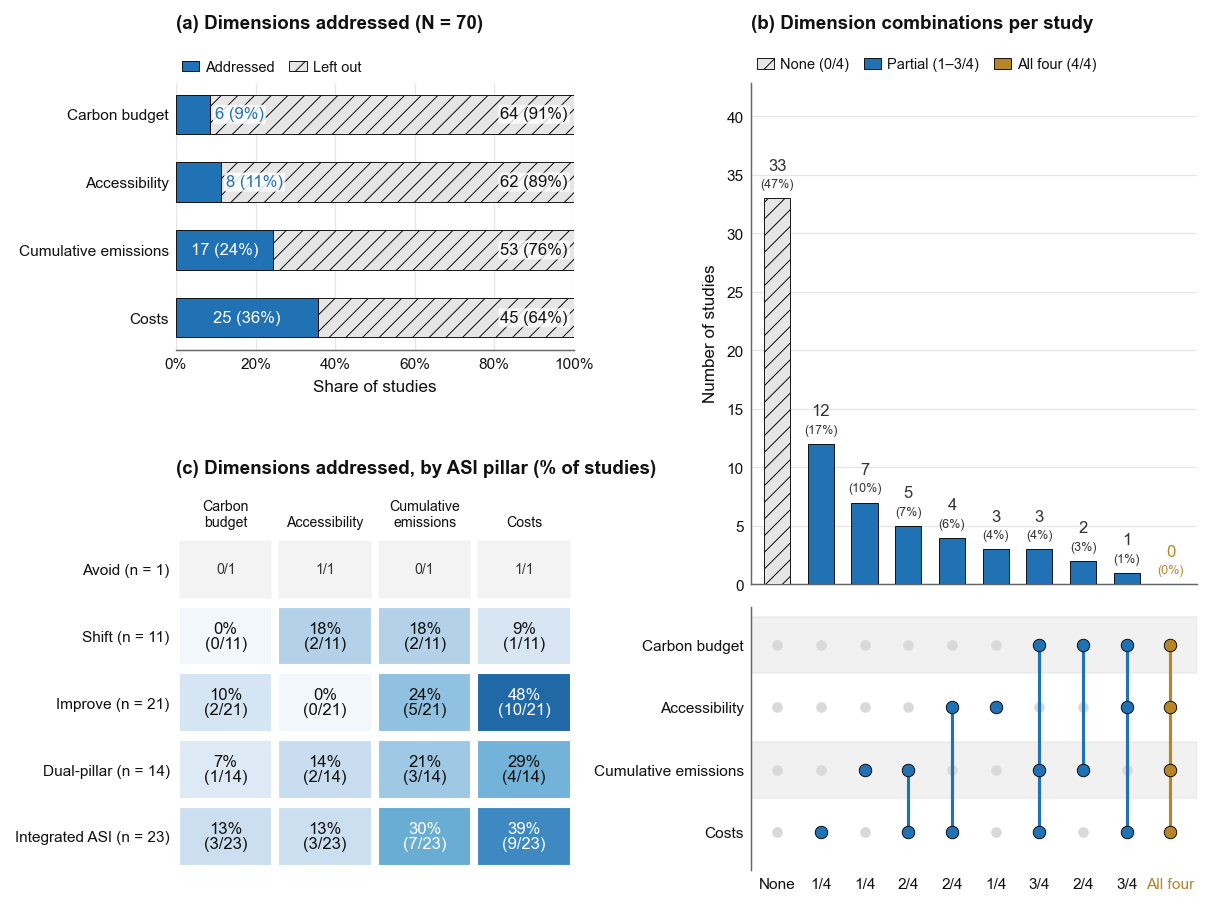

In [3]:
# %% [FIGURA 3.5 – WHAT THE LITERATURE LEAVES OUT] Cobertura de dimensiones + por pilar ASI + intersecciones (N = 70)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import LinearSegmentedColormap

# ==============================================================================
# 0. RUTAS, PARÁMETROS Y LECTURA ESTRICTA DEL DATASET
# ==============================================================================
DARK_MODE = False
FS = 1.0                      # Escala de TODAS las fuentes
FIGSIZE = (8.4, 6.4)          # 8.4 in de ancho -> \textwidth (factor 0.75), como el resto de figuras
MIN_N_ROW = 3                 # pilares con n < 3 no se porcentúan (se muestran atenuados)

INFILE = Path("/Users/joanpau/Documents/00_Inbox/SLR - Results Points/SLR Extraction Sheet.xlsx")
if not INFILE.exists():
    raise FileNotFoundError(f"No se encontró el archivo en: {INFILE}")
OUTDIR = INFILE.parent / "Images"
OUTDIR.mkdir(exist_ok=True)

df = pd.read_excel(INFILE, sheet_name="Extraction").dropna(subset=["ID"])
df["ID"] = df["ID"].astype(str).str.strip()
N_TOTAL = len(df)
assert df["ID"].is_unique, "IDs duplicados en el dataset"

DIM_NAMES = ["Cumulative emissions", "Carbon budget", "Costs", "Accessibility"]
missing = [c for c in DIM_NAMES if c not in df.columns]
assert not missing, f"Faltan columnas en 'Extraction': {missing}"

def yn_flag(series, name):
    """Y -> True, N -> False. Cualquier otro valor (vacío, 'Partial', ...) detiene el script:
    así ningún estudio se cuenta en silencio como incluido u omitido."""
    s = series.fillna("").astype(str).str.strip().str.upper()
    bad = sorted(set(s) - {"Y", "N"})
    assert not bad, f"Valores no Y/N en '{name}': {bad} -> IDs {df.loc[~s.isin(['Y', 'N']), 'ID'].tolist()}"
    return s.eq("Y")

flags = pd.DataFrame({d: yn_flag(df[d], d) for d in DIM_NAMES})
flags.index = df["ID"]

ASI_5_ORDER = ["Avoid", "Shift", "Improve", "Dual-pillar", "Integrated ASI"]
PILLAR_5_MAP = {"A": "Avoid", "S": "Shift", "I": "Improve",
                "A+S": "Dual-pillar", "A+I": "Dual-pillar", "S+I": "Dual-pillar",
                "A+S+I": "Integrated ASI"}
pillar = df["Pillar"].astype(str).str.strip().map(PILLAR_5_MAP)
pillar.index = df["ID"]
assert pillar.isna().sum() == 0, f"Pilares sin mapear: {pillar[pillar.isna()].index.tolist()}"

# ==============================================================================
# 1. PALETA Y TIPOGRAFÍA (misma familia que el resto del paper)
# ==============================================================================
BG_COL    = "#000000" if DARK_MODE else "#FFFFFF"
FG_COL    = "#FFFFFF" if DARK_MODE else "#111111"
SUB_COL   = "#D9D9D9" if DARK_MODE else "#333333"
EDGE_COL  = "#FFFFFF" if DARK_MODE else "#000000"
GRID_COL  = "#222222" if DARK_MODE else "0.90"
SPINE_COL = "#888888" if DARK_MODE else "0.40"
BLUE_INC  = "#2b7bba" if DARK_MODE else "#2171b5"
GREY_OMIT = "#262626" if DARK_MODE else "#e6e6e6"
GOLD_ALL4 = "#f2be54" if DARK_MODE else "#b88428"
DOT_OFF   = "#3a3a3a" if DARK_MODE else "#d9d9d9"
HEAT_CMAP = LinearSegmentedColormap.from_list("blues_paper", ["#f2f7fc", "#c6dbef", "#6baed6",
                                                              "#2171b5", "#1f3f63"])

F_TITLE, F_LABEL, F_TICK, F_LEG, F_ANN = 9.0 * FS, 8.2 * FS, 7.4 * FS, 7.0 * FS, 6.8 * FS
F_NUM = 8.0 * FS              # tamaño de los números (etiquetas de datos)
# Solo los títulos de panel van en negrita; etiquetas y números en regular.
TITLE_PAD = 26 * FS

# Arial primero: en macOS "Helvetica.ttc" no expone la negrita a matplotlib.
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": F_TICK, "axes.labelsize": F_LABEL, "axes.titlesize": F_TITLE,
    "xtick.labelsize": F_TICK, "ytick.labelsize": F_TICK, "legend.fontsize": F_LEG,
    "axes.linewidth": 0.7, "hatch.linewidth": 0.45, "hatch.color": EDGE_COL,
    "figure.facecolor": BG_COL, "axes.facecolor": BG_COL, "savefig.facecolor": BG_COL,
    "text.color": FG_COL, "axes.labelcolor": FG_COL, "xtick.color": FG_COL, "ytick.color": FG_COL,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

def clean_ax(ax, grid_axis=None):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(SPINE_COL)
    ax.spines["bottom"].set_color(SPINE_COL)
    if grid_axis == "y":
        ax.yaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    elif grid_axis == "x":
        ax.xaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=FG_COL)

def panel_title(ax, text, pad=TITLE_PAD):
    ax.set_title(text, fontsize=F_TITLE, fontweight="bold", pad=pad, loc="left", color=FG_COL)

def top_legend(ax, handles, ncol):
    leg = ax.legend(handles=handles, ncol=ncol, frameon=False, fontsize=F_LEG, handlelength=1.2,
                    columnspacing=1.0, handletextpad=0.4, loc="lower left",
                    bbox_to_anchor=(0.0, 1.01), borderaxespad=0)
    for txt in leg.get_texts():
        txt.set_color(FG_COL)
    return leg

# ==============================================================================
# 2. MAQUETACIÓN: izquierda = cobertura (arriba) + por pilar (abajo) | derecha = intersecciones
# ==============================================================================
fig = plt.figure(figsize=FIGSIZE, dpi=150, facecolor=BG_COL)
gs_main = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.0, 1.12], wspace=0.42,
                            left=0.17, right=0.98, top=0.90, bottom=0.08)
gs_l = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs_main[0], height_ratios=[1.0, 1.25],
                                        hspace=0.62)
gs_r = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs_main[1], height_ratios=[2.2, 1.15],
                                        hspace=0.06)
ax_a = fig.add_subplot(gs_l[0])
ax_c = fig.add_subplot(gs_l[1])
ax_b_top = fig.add_subplot(gs_r[0])
ax_b_mat = fig.add_subplot(gs_r[1], sharex=ax_b_top)

# ------------------------------------------------------------------------------
# PANEL (a): Dimensiones abordadas vs omitidas (N = 70)
# ------------------------------------------------------------------------------
inc_counts = flags.sum().reindex(DIM_NAMES).values.astype(int)
omit_counts = N_TOTAL - inc_counts
order_a = np.argsort(-omit_counts, kind="stable")[::-1]        # mayor omisión arriba
dims_sorted = [DIM_NAMES[i] for i in order_a]
inc_sorted, omit_sorted = inc_counts[order_a], omit_counts[order_a]
inc_pct, omit_pct = 100.0 * inc_sorted / N_TOTAL, 100.0 * omit_sorted / N_TOTAL

y_a = np.arange(len(dims_sorted))
ax_a.barh(y_a, inc_pct, height=0.58, color=BLUE_INC, edgecolor=EDGE_COL, linewidth=0.42,
          zorder=3)
ax_a.barh(y_a, omit_pct, left=inc_pct, height=0.58, color=GREY_OMIT, edgecolor=EDGE_COL,
          linewidth=0.42, hatch="///", zorder=3)
for yi, ic, ip, oc, op in zip(y_a, inc_sorted, inc_pct, omit_sorted, omit_pct):
    if ip >= 16:
        ax_a.text(ip / 2, yi, f"{ic} ({ip:.0f}%)", va="center", ha="center", fontsize=F_NUM,
                  color="#FFFFFF", zorder=4)
    else:                                       # barra estrecha: etiqueta justo a su derecha
        ax_a.text(ip + 1.2, yi, f"{ic} ({ip:.0f}%)", va="center", ha="left", fontsize=F_NUM,
                  color=BLUE_INC, zorder=4,
                  bbox=dict(boxstyle="round,pad=0.12", facecolor=BG_COL, edgecolor="none",
                            alpha=0.85))
    ax_a.text(100 - 1.5, yi, f"{oc} ({op:.0f}%)", va="center", ha="right", fontsize=F_NUM,
              color=FG_COL, zorder=4,
              bbox=dict(boxstyle="round,pad=0.12", facecolor=BG_COL, edgecolor="none", alpha=0.8))

ax_a.set_yticks(y_a)
ax_a.set_yticklabels(dims_sorted)
ax_a.set_xlim(0, 100)
ax_a.set_xticks(range(0, 101, 20))
ax_a.set_xticklabels([f"{v}%" for v in range(0, 101, 20)])
ax_a.set_xlabel("Share of studies", fontsize=F_LABEL)
clean_ax(ax_a, grid_axis="x")
ax_a.spines["left"].set_visible(False)
panel_title(ax_a, f"(a) Dimensions addressed (N = {N_TOTAL})")
top_legend(ax_a, [Patch(facecolor=BLUE_INC, edgecolor=EDGE_COL, linewidth=0.42,
                        label="Addressed"),
                  Patch(facecolor=GREY_OMIT, edgecolor=EDGE_COL, linewidth=0.42, hatch="///",
                        label="Left out")], ncol=2)

# ------------------------------------------------------------------------------
# PANEL (c): Cobertura de cada dimensión por pilar ASI (% de estudios del pilar)
# ------------------------------------------------------------------------------
heat_rows = ASI_5_ORDER
n_pillar = pillar.value_counts().reindex(heat_rows).fillna(0).astype(int)
k_pd = flags.groupby(pillar).sum().reindex(index=heat_rows, columns=DIM_NAMES).fillna(0).astype(int)
pct_pd = k_pd.div(n_pillar, axis=0) * 100
dims_c = dims_sorted[::-1]                              # mismo orden que el panel superior (arriba->abajo)

for i, p in enumerate(heat_rows):
    for j, d in enumerate(dims_c):
        k, n = int(k_pd.loc[p, d]), int(n_pillar[p])
        small = n < MIN_N_ROW
        val = pct_pd.loc[p, d]
        fc = GREY_OMIT if small else HEAT_CMAP(min(val, 60) / 60)
        ax_c.add_patch(plt.Rectangle((j - 0.47, i - 0.44), 0.94, 0.88, facecolor=fc,
                                     edgecolor=BG_COL, linewidth=1.0, alpha=0.45 if small else 1))
        if small:
            txt, col = f"{k}/{n}", SUB_COL
        else:
            txt = f"{val:.0f}%\n({k}/{n})"
            col = "#FFFFFF" if val >= 30 else FG_COL
        ax_c.text(j, i, txt, ha="center", va="center", fontsize=F_NUM if not small else F_ANN,
                  color=col, linespacing=1.0)

ax_c.set_xlim(-0.5, len(dims_c) - 0.5)
ax_c.set_ylim(len(heat_rows) - 0.5, -0.5)
ax_c.set_xticks(range(len(dims_c)))
ax_c.set_xticklabels([d.replace(" ", "\n", 1) for d in dims_c], fontsize=F_ANN)
ax_c.xaxis.tick_top()
ax_c.set_yticks(range(len(heat_rows)))
ax_c.set_yticklabels([f"{p} (n = {n_pillar[p]})" for p in heat_rows])
for s in ax_c.spines.values():
    s.set_visible(False)
ax_c.tick_params(length=0, pad=3)
panel_title(ax_c, "(c) Dimensions addressed, by ASI pillar (% of studies)", pad=30 * FS)

# ------------------------------------------------------------------------------
# PANEL (b): Intersecciones entre dimensiones (UpSet, N = 70)
# ------------------------------------------------------------------------------
combos = flags[DIM_NAMES].value_counts().reset_index(name="count")
combos["n_active"] = combos[DIM_NAMES].sum(axis=1)
if not (combos["n_active"] == 4).any():                 # la intersección completa se muestra aunque sea 0
    combos = pd.concat([combos, pd.DataFrame([{**{d: True for d in DIM_NAMES},
                                               "count": 0, "n_active": 4}])], ignore_index=True)
combos_non4 = combos[combos["n_active"] < 4].sort_values(
    ["count", "n_active"] + DIM_NAMES, ascending=[False, True] + [False] * len(DIM_NAMES))
combos = pd.concat([combos_non4, combos[combos["n_active"] == 4]], ignore_index=True)
assert int(combos["count"].sum()) == N_TOTAL, "La suma de combinaciones no coincide con N"

x_b = np.arange(len(combos))
def combo_color(n):
    return GOLD_ALL4 if n == 4 else (GREY_OMIT if n == 0 else BLUE_INC)

for xi, row in combos.iterrows():
    ax_b_top.bar(xi, row["count"], width=0.6, color=combo_color(row["n_active"]),
                 edgecolor=EDGE_COL, linewidth=0.42, hatch="///" if row["n_active"] == 0 else "",
                 zorder=3)
    cnt = int(row["count"])
    col_lbl = GOLD_ALL4 if row["n_active"] == 4 else SUB_COL
    y_lbl = cnt + combos["count"].max() * 0.02
    # número grande arriba; porcentaje debajo y algo menor para que no choque con la barra vecina
    ax_b_top.annotate(f"{cnt}", (xi, y_lbl), xytext=(0, 8.5 * FS), textcoords="offset points",
                      ha="center", va="bottom", fontsize=F_NUM, color=col_lbl)
    ax_b_top.text(xi, y_lbl, f"({100 * cnt / N_TOTAL:.0f}%)", ha="center", va="bottom",
                  fontsize=F_ANN - 0.8, color=col_lbl)

ax_b_top.set_ylabel("Number of studies", fontsize=F_LABEL)
ax_b_top.set_ylim(0, combos["count"].max() * 1.30)
ax_b_top.yaxis.set_major_locator(MaxNLocator(integer=True))
clean_ax(ax_b_top, grid_axis="y")
plt.setp(ax_b_top.get_xticklabels(), visible=False)
panel_title(ax_b_top, "(b) Dimension combinations per study")
top_legend(ax_b_top, [
    Patch(facecolor=GREY_OMIT, edgecolor=EDGE_COL, linewidth=0.42, hatch="///", label="None (0/4)"),
    Patch(facecolor=BLUE_INC, edgecolor=EDGE_COL, linewidth=0.42, label="Partial (1–3/4)"),
    Patch(facecolor=GOLD_ALL4, edgecolor=EDGE_COL, linewidth=0.42, label="All four (4/4)")],
    ncol=3)

# Matriz de intersección
mat_dims = dims_c[::-1]                                   # misma ordenación que los otros paneles
y_mat = np.arange(len(mat_dims))
for yi in y_mat:
    if yi % 2 == 1:
        ax_b_mat.axhspan(yi - 0.45, yi + 0.45, color=GRID_COL, alpha=0.55, zorder=0)
for xi, row in combos.iterrows():
    on = [yi for yi, d in enumerate(mat_dims) if row[d]]
    off = [yi for yi, d in enumerate(mat_dims) if not row[d]]
    ax_b_mat.scatter([xi] * len(off), off, s=26, color=DOT_OFF, zorder=2, linewidths=0)
    if on:
        col = GOLD_ALL4 if row["n_active"] == 4 else BLUE_INC
        if len(on) > 1:
            ax_b_mat.plot([xi, xi], [min(on), max(on)], color=col, linewidth=1.5, zorder=3)
        ax_b_mat.scatter([xi] * len(on), on, s=36, color=col, edgecolor=EDGE_COL,
                         linewidth=0.42, zorder=4)

x_labels = ["None" if r["n_active"] == 0 else ("All four" if r["n_active"] == 4
            else f"{int(r['n_active'])}/4") for _, r in combos.iterrows()]
ax_b_mat.set_yticks(y_mat)
ax_b_mat.set_yticklabels(mat_dims, fontsize=F_TICK)
ax_b_mat.set_ylim(-0.6, len(mat_dims) - 0.4)
ax_b_mat.set_xticks(x_b)
ax_b_mat.set_xticklabels(x_labels, fontsize=F_TICK)
ax_b_mat.set_xlim(-0.6, len(combos) - 0.4)
for s in ["top", "right", "bottom"]:
    ax_b_mat.spines[s].set_visible(False)
ax_b_mat.spines["left"].set_color(SPINE_COL)          # barra que separa las etiquetas de la matriz
ax_b_mat.tick_params(length=0, colors=FG_COL)
for t in ax_b_mat.get_xticklabels():
    if t.get_text() == "All four":
        t.set_color(GOLD_ALL4)

# ==============================================================================
# 3. EXPORTACIÓN Y CIFRAS PARA EL TEXTO (todas leídas del dataset)
# ==============================================================================
stem = f"fig_literature_gaps{N_TOTAL}" + ("_dark" if DARK_MODE else "")
for ext in ["pdf", "png", "svg"]:
    fig.savefig(OUTDIR / f"{stem}.{ext}", dpi=600 if ext == "png" else 300,
                bbox_inches="tight", pad_inches=0.04, facecolor=BG_COL, edgecolor="none")

n_dims = flags.sum(axis=1)
print(f"Archivos guardados en: {OUTDIR}/{stem}.{{pdf,png,svg}}")
print(f"\nN = {N_TOTAL}")
print("Estudios que abordan cada dimensión:", dict(zip(DIM_NAMES, flags.sum().astype(int))))
print("Nº de dimensiones por estudio:", n_dims.value_counts().sort_index().to_dict())
print("Las cuatro:", int((n_dims == 4).sum()), "| ninguna:", int((n_dims == 0).sum()))
print("\nPor pilar (k de n):\n", k_pd.assign(n=n_pillar).to_string())
print("\nEstudios con >= 3 dimensiones:", n_dims[n_dims >= 3].index.tolist())
plt.show()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Exportación completada (N = 70 artículos)
Archivos guardados en: /Users/joanpau/Documents/00_Inbox/SLR - Results Points/Images/fig_literature_gaps_all70.{pdf,png,svg}


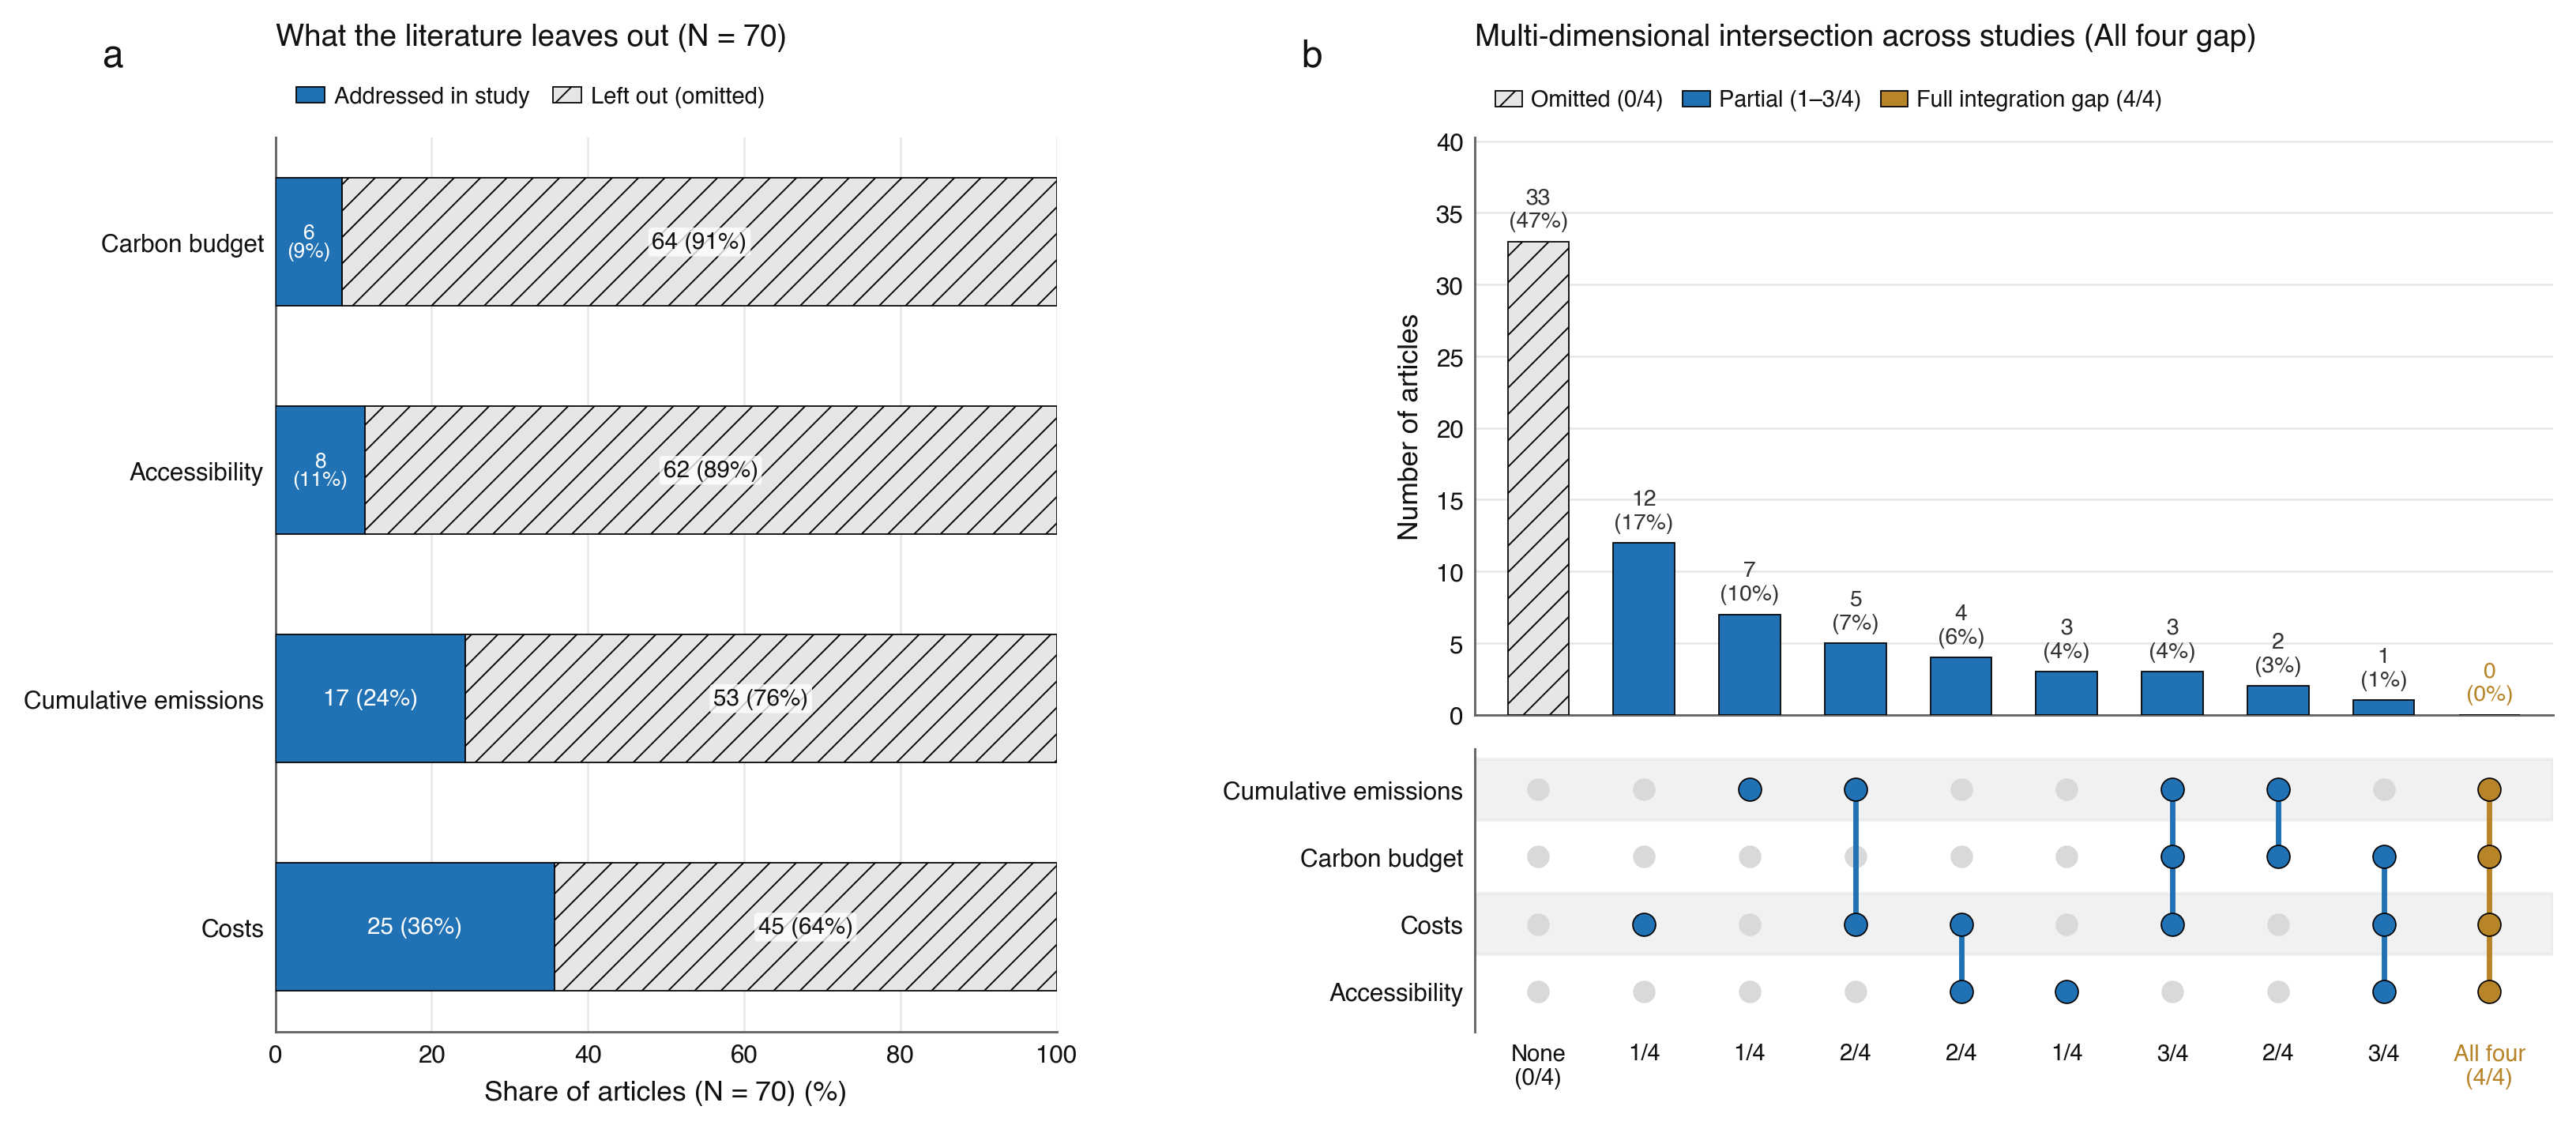

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from matplotlib.ticker import MaxNLocator

# ==============================================================================
# 1. PALETAS Y TIPOGRAFÍA EDITORIAL (UNIFICADA CON FIGURA 1)
# ==============================================================================
BG_COL    = "#000000" if DARK_MODE else "#FFFFFF"
FG_COL    = "#FFFFFF" if DARK_MODE else "#111111"
SUB_COL   = "#D9D9D9" if DARK_MODE else "#333333"
EDGE_COL  = "#FFFFFF" if DARK_MODE else "#000000"
GRID_COL  = "#222222" if DARK_MODE else "0.90"
SPINE_COL = "#888888" if DARK_MODE else "0.40"

BLUE_INC  = "#2b7bba" if DARK_MODE else "#2171b5"
GREY_OMIT = "#262626" if DARK_MODE else "#e6e6e6"
GOLD_ALL4 = "#f2be54" if DARK_MODE else "#b88428"
DOT_OFF   = "#3a3a3a" if DARK_MODE else "#d9d9d9"

plt.rcParams.update({
    "font.family":       "sans-serif",
    "font.sans-serif":   ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size":         8.0,
    "axes.labelsize":    8.5,
    "axes.titlesize":    9.2,
    "xtick.labelsize":   7.5,
    "ytick.labelsize":   7.5,
    "legend.fontsize":   7.0,
    "axes.linewidth":    0.7,
    "hatch.linewidth":   0.45,
    "hatch.color":       EDGE_COL,
    "figure.facecolor":  BG_COL,
    "axes.facecolor":    BG_COL,
    "savefig.facecolor": BG_COL,
    "text.color":        FG_COL,
    "axes.labelcolor":   FG_COL,
    "xtick.color":       FG_COL,
    "ytick.color":       FG_COL,
    "pdf.fonttype":      42,
    "ps.fonttype":       42,
})

def clean_ax(ax, grid_axis=None):
    ax.set_facecolor(BG_COL)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(SPINE_COL)
    ax.spines["bottom"].set_color(SPINE_COL)
    if grid_axis == "y":
        ax.yaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    elif grid_axis == "x":
        ax.xaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=FG_COL)

# ==============================================================================
# 2. CONSTRUCCIÓN DE LA FIGURA 2 (N = 70 ARTÍCULOS)
# ==============================================================================
fig = plt.figure(figsize=(12.4, 4.9), dpi=300, facecolor=BG_COL)
gs_main = gridspec.GridSpec(1, 2, width_ratios=[1.0, 1.38], wspace=0.45)

ax_a = fig.add_subplot(gs_main[0, 0])
gs_b = gridspec.GridSpecFromSubplotSpec(
    2, 1, subplot_spec=gs_main[0, 1], height_ratios=[2.35, 1.15], hspace=0.08
)
ax_b_top = fig.add_subplot(gs_b[0])
ax_b_mat = fig.add_subplot(gs_b[1], sharex=ax_b_top)

# ------------------------------------------------------------------------------
# PANEL a: Cobertura vs. Omisión por dimensión analítica (N = 70)
# ------------------------------------------------------------------------------
DIM_NAMES = ["Cumulative emissions", "Carbon budget", "Costs", "Accessibility"]
inc_counts  = np.array([int(flags[d].sum()) for d in DIM_NAMES])
omit_counts = N_TOTAL - inc_counts

# Ordenar de menor a mayor omisión (dejando la mayor brecha arriba)
order_a = np.argsort(omit_counts)
dims_sorted = [DIM_NAMES[i] for i in order_a]
inc_sorted  = inc_counts[order_a]
omit_sorted = omit_counts[order_a]

inc_pct  = 100.0 * inc_sorted / N_TOTAL
omit_pct = 100.0 * omit_sorted / N_TOTAL

y_a = np.arange(len(dims_sorted))
ax_a.barh(y_a, inc_pct, height=0.56, color=BLUE_INC, edgecolor=EDGE_COL,
          linewidth=0.42, label="Addressed in study", zorder=3)
ax_a.barh(y_a, omit_pct, left=inc_pct, height=0.56, color=GREY_OMIT, edgecolor=EDGE_COL,
          linewidth=0.42, hatch="///", label="Left out (omitted)", zorder=3)

for yi, (ic, ip, oc, op) in enumerate(zip(inc_sorted, inc_pct, omit_sorted, omit_pct)):
    if ip >= 16:
        ax_a.text(ip / 2, yi, f"{ic} ({ip:.0f}%)", va="center", ha="center",
                  fontsize=7.1, fontweight="bold", color="#FFFFFF", zorder=4)
    elif ip > 0:
        ax_a.text(ip / 2, yi, f"{ic}\n({ip:.0f}%)", va="center", ha="center",
                  fontsize=6.3, fontweight="bold", color="#FFFFFF", linespacing=0.95, zorder=4)

    if op >= 16:
        ax_a.text(ip + op / 2, yi, f"{oc} ({op:.0f}%)", va="center", ha="center",
                  fontsize=7.1, fontweight="bold", color=FG_COL, zorder=4,
                  bbox=dict(boxstyle="round,pad=0.16", facecolor=BG_COL, edgecolor="none",
                            alpha=0.86 if DARK_MODE else 0.78))

ax_a.set_yticks(y_a)
ax_a.set_yticklabels(dims_sorted, fontweight="bold", color=FG_COL)
ax_a.set_xlim(0, 100)
ax_a.set_xlabel(f"Share of articles (N = {N_TOTAL}) (%)", fontsize=8.5, color=FG_COL)
ax_a.set_title(f"What the literature leaves out (N = {N_TOTAL})",
               fontsize=9.2, fontweight="bold", pad=28, loc="left", color=FG_COL)
clean_ax(ax_a, grid_axis="x")

leg_a = ax_a.legend(ncol=2, frameon=False, fontsize=7.0, handlelength=1.25,
                    columnspacing=1.0, handletextpad=0.4, labelcolor=FG_COL,
                    loc="lower left", bbox_to_anchor=(0.0, 1.01))
for patch in leg_a.get_patches():
    patch.set_linewidth(0.42)
    patch.set_edgecolor(EDGE_COL)

# ------------------------------------------------------------------------------
# PANEL b: Intersección multidimensional entre estudios (UpSet-style, N = 70)
# ------------------------------------------------------------------------------
combos = (flags[DIM_NAMES]
          .value_counts()
          .reset_index(name="count"))
combos["n_active"] = combos[DIM_NAMES].sum(axis=1)

# Garantizar que la intersección completa "All four" (4/4) aparezca explícitamente
if not (combos["n_active"] == 4).any():
    zero_all4 = pd.DataFrame([{**{d: True for d in DIM_NAMES}, "count": 0, "n_active": 4}])
    combos = pd.concat([combos, zero_all4], ignore_index=True)

# Ordenación determinista: frecuencia descendente, luego complejidad ascendente, dejando 4/4 al final
combos_non4 = (combos[combos["n_active"] < 4]
               .sort_values(["count", "n_active"] + DIM_NAMES,
                            ascending=[False, True, False, False, False, False]))
combos_all4 = combos[combos["n_active"] == 4]
combos = pd.concat([combos_non4, combos_all4], ignore_index=True)

assert int(combos["count"].sum()) == N_TOTAL, "La suma de combinaciones no coincide con N_TOTAL"

x_b = np.arange(len(combos))
bar_colors = []
for _, row in combos.iterrows():
    if row["n_active"] == 4:
        bar_colors.append(GOLD_ALL4)
    elif row["n_active"] == 0:
        bar_colors.append(GREY_OMIT)
    else:
        bar_colors.append(BLUE_INC)



bars_b = ax_b_top.bar(x_b, combos["count"], width=0.58, color=bar_colors,
                      edgecolor=EDGE_COL, linewidth=0.42, zorder=3)

for idx, row in combos.iterrows():
    if row["n_active"] == 0:
        bars_b[idx].set_hatch("///")

for xi, row in combos.iterrows():
    cnt = int(row["count"])
    pct = 100.0 * cnt / N_TOTAL
    lbl = f"{cnt}\n({pct:.0f}%)" if cnt > 0 else "0\n(0%)"
    col_txt = GOLD_ALL4 if row["n_active"] == 4 else SUB_COL
    fw = "bold" if row["n_active"] in (0, 4) else "normal"
    ax_b_top.text(xi, cnt + max(combos["count"].max() * 0.02, 0.55), lbl,
                  ha="center", va="bottom", fontsize=6.8, color=col_txt, fontweight=fw)

ax_b_top.set_ylabel("Number of articles", fontsize=8.5, color=FG_COL)
ax_b_top.set_ylim(0, max(combos["count"].max() * 1.22, 6))
ax_b_top.yaxis.set_major_locator(MaxNLocator(integer=True))
ax_b_top.set_title("Multi-dimensional intersection across studies (All four gap)",
                   fontsize=9.2, fontweight="bold", pad=28, loc="left", color=FG_COL)
clean_ax(ax_b_top, grid_axis="y")
plt.setp(ax_b_top.get_xticklabels(), visible=False)

leg_b_handles = [
    mpatches.Patch(facecolor=GREY_OMIT, edgecolor=EDGE_COL, linewidth=0.42, hatch="///", label="Omitted (0/4)"),
    mpatches.Patch(facecolor=BLUE_INC, edgecolor=EDGE_COL, linewidth=0.42, label="Partial (1–3/4)"),
    mpatches.Patch(facecolor=GOLD_ALL4, edgecolor=EDGE_COL, linewidth=0.42, label="Full integration gap (4/4)"),
]
ax_b_top.legend(handles=leg_b_handles, ncol=3, frameon=False, fontsize=6.9,
                handlelength=1.2, columnspacing=0.85, handletextpad=0.38,
                labelcolor=FG_COL, loc="lower left", bbox_to_anchor=(0.0, 1.01))

# --- Matriz de intersección inferior ---
ax_b_mat.set_facecolor(BG_COL)
for s in ["top", "right", "bottom"]:
    ax_b_mat.spines[s].set_visible(False)
ax_b_mat.spines["left"].set_color(SPINE_COL)
ax_b_mat.tick_params(length=0, colors=FG_COL)

mat_dims = DIM_NAMES[::-1]
y_mat = np.arange(len(mat_dims))

for yi in y_mat:
    if yi % 2 == 1:
        ax_b_mat.axhspan(yi - 0.45, yi + 0.45, color=GRID_COL, alpha=0.55, zorder=0)

for xi, row in combos.iterrows():
    active_ys = [yi for yi, d in enumerate(mat_dims) if row[d]]
    inactive_ys = [yi for yi, d in enumerate(mat_dims) if not row[d]]

    ax_b_mat.scatter([xi] * len(inactive_ys), inactive_ys, s=34, color=DOT_OFF, zorder=2)

    if active_ys:
        pt_col = GOLD_ALL4 if row["n_active"] == 4 else BLUE_INC
        if len(active_ys) > 1:
            ax_b_mat.plot([xi, xi], [min(active_ys), max(active_ys)],
                          color=pt_col, linewidth=1.65, zorder=3)
        ax_b_mat.scatter([xi] * len(active_ys), active_ys, s=48, color=pt_col,
                         edgecolor=EDGE_COL, linewidth=0.42, zorder=4)

x_labels = []
for _, row in combos.iterrows():
    if row["n_active"] == 0:
        x_labels.append("None\n(0/4)")
    elif row["n_active"] == 4:
        x_labels.append("All four\n(4/4)")
    else:
        x_labels.append(f"{int(row['n_active'])}/4")

ax_b_mat.set_yticks(y_mat)
ax_b_mat.set_yticklabels(mat_dims, fontsize=7.5, fontweight="bold", color=FG_COL)
ax_b_mat.set_ylim(-0.6, len(mat_dims) - 0.4)
ax_b_mat.set_xticks(x_b)
ax_b_mat.set_xticklabels(x_labels, fontsize=7.0, fontweight="bold", color=FG_COL)
ax_b_mat.set_xlim(-0.6, len(combos) - 0.4)

for tick_lbl in ax_b_mat.get_xticklabels():
    if "All four" in tick_lbl.get_text():
        tick_lbl.set_color(GOLD_ALL4)

# ==============================================================================
# 3. ALINEACIÓN EXACTA DE LETRAS DE PANEL (a, b) Y EXPORTACIÓN MULTIFORMATO
# ==============================================================================
fig.canvas.draw()
col1_x = ax_a.get_position().x0 - 0.052
col2_x = ax_b_top.get_position().x0 - 0.052
row1_y = ax_a.get_position().y1 + 0.055

for x_fig, y_fig, letter in [
    (col1_x, row1_y, "a"),
    (col2_x, row1_y, "b"),
]:
    fig.text(x_fig, y_fig, letter, transform=fig.transFigure,
             fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=FG_COL)

suffix = "_dark" if DARK_MODE else ""
stem = f"fig_literature_gaps_all{N_TOTAL}{suffix}"

for ext in ["pdf", "png", "svg"]:
    out_file = OUTDIR / f"{stem}.{ext}"
    fig.savefig(
        out_file,
        dpi=600 if ext == "png" else 300,
        bbox_inches="tight",
        facecolor=BG_COL,
        edgecolor="none",
    )

print(f"Exportación completada (N = {N_TOTAL} artículos)")
print(f"Archivos guardados en: {OUTDIR}/{stem}.{{pdf,png,svg}}")
plt.show()